# Can LLM-scored news predict commodity futures returns?
### Text, macro and price signals traded with a cost-aware dynamic portfolio

*Machine Learning for Portfolio Management and Trading — course project*
Goueudeupouh Diomande · Jude Nemer Khazzaka

| § | Content | Project step | Framework segment |
|---|---|---|---|
| 1 | Question, hypotheses, contributions, main results, literature | 1 | Introduction |
| 2 | Data extraction and cleaning (text scored with an LLM, prices, macro) | 2–3 | Dataset overview |
| 3 | Exploratory analysis and data checks | 4 | Dataset overview |
| 4 | Target, sample split and feature sets | 5 | Learning strategy |
| 5 | Return prediction: Ridge baseline, Random Forest, LightGBM | 6 | Learning strategy |
| 6 | Portfolio: dynamic mean-variance with transaction costs | 7 | Learning strategy |
| 7 | Backtest and results on the validation sample, attribution | 8–9 | Baseline results |
| 8 | Robustness: costs, liquidity, regime break, significance | 10 | Robustness |
| 9 | Frozen specification and out-of-sample test | 8–9 | Baseline results |
| 10 | Conclusion | 11 | Conclusion |

**Running the notebook.** With the default switches (all `False`) the notebook loads the files already
generated in `data_cleaning/`: no API key, no internet, a few minutes on a laptop. It needs the course
library `skfin`, including `skfin/backtesting_with_cost.py`, which is written by the `%%writefile` cell of
the course notebook `30_Transaction_cost.ipynb`.

> **Executed notebook.** The outputs below come from one complete run, in order (execution counts 1–53), on
> the files in `data_cleaning/`. Every number quoted in the markdown is taken from these outputs. If the
> notebook is rerun on different input files (for example after `DOWNLOAD_MACRO = True`), check the readings again.

# 1. Introduction

**Context.** Commodity futures react to information that is mostly published as text: OPEC decisions,
central-bank communication, weather and harvest reports, wars. Text-based signals are well documented for
equities (Tetlock, 2007) and for crude oil (Brandt & Gao, 2019), and large language models now make it
possible to score each article directly for its expected price impact (Lopez-Lira & Tang, 2023). Two gaps
remain. Most LLM studies stop at the forecast and do not ask whether the signal survives portfolio
construction and trading costs. And LLM scores can carry look-ahead bias, because the model may know how
the events turned out (Glasserman & Lin, 2023).

**Question.** Does weekly news, scored by an LLM for each commodity, predict next-week futures returns
beyond what prices and macro data already contain, and is the signal still worth trading once it goes
through a cost-aware dynamic optimiser?

**Hypotheses.**

| | Hypothesis |
|---|---|
| H1 | News features add predictability beyond prices |
| H2 | Macro features add predictability beyond prices and news |
| H3 | The dynamic (cost-aware) optimiser beats the myopic one, net of costs |
| H4 | The result survives the out-of-sample test, sub-periods and multiple testing |

**Contributions.**
- *Data.* An original weekly panel (2010–2026) for five futures — WTI crude oil, natural gas, gold, copper,
  wheat — combining nine text sources scored article by article with `gpt-4o-mini`, front-month futures
  prices and six FRED macro series. Every step is code; LLM scores are cached so the dataset is reproducible
  without calling the model again.
- *Design.* Three nested feature sets (price ⊂ price+news ⊂ price+news+macro) × three models (Ridge baseline,
  Random Forest, LightGBM), on identical windows, so that the value of each block is isolated.
- *Portfolio.* Mean-variance with quadratic transaction costs (Gârleanu & Pedersen, 2013; course chapter 30),
  where yesterday's holdings enter today's solution, compared with the myopic optimiser across cost levels.
- *Discipline.* Train / validation / test split, specification frozen before the test, standard errors on
  every Sharpe ratio, and an explicit count of the configurations tried.

**Main results.**
- Weekly returns are hard to predict: validation $R^2_{oos}$ is at most 1.4 % (Random Forest C, crude oil), and
  only Ridge on crude oil (IC 0.18–0.19) clears the two-standard-error band — with near-constant predictions,
  since its penalty sits at the top of the grid.
- **H1 (news): not supported.** Adding news changes the dynamic net Sharpe by +0.13 (Random Forest), −0.004
  (LightGBM) and −0.90 (Ridge).
- **H2 (macro): supported in validation.** Adding macro raises the dynamic net Sharpe for all three models:
  +0.48 (LightGBM), +0.16 (Random Forest), +0.23 (Ridge), and raises the copper IC for all three.
- **H3 (dynamic optimiser): supported in direction, small in size.** Net Sharpe is higher in 7 of 9
  configurations, unchanged in one and lower by 0.006 in one; the gap grows with costs (+0.066 at 4× costs for
  Ridge C) and holding periods lengthen in all nine.
- **H4 (out of sample): positive, not significant.** The frozen Random Forest C dynamic strategy earns a
  **net Sharpe of 0.595 on test (2023–2026)** versus 0.715 on validation, with $t \approx 1.06$; 2023 accounts
  for about **55 %** of the test net PnL.

**Literature and resources.**
- Tetlock (2007), *Giving content to investor sentiment*, Journal of Finance — media tone predicts returns.
- Brandt & Gao (2019), *Macro fundamentals or geopolitical events? A textual analysis of news events for crude oil*, Journal of Empirical Finance.
- Lopez-Lira & Tang (2023), *Can ChatGPT forecast stock price movements?*, SSRN / arXiv.
- Glasserman & Lin (2023), *Assessing look-ahead bias in stock return predictions generated by GPT sentiment analysis*, arXiv.
- Moskowitz, Ooi & Pedersen (2012), *Time series momentum*, Journal of Financial Economics — motivates the momentum features.
- Gu, Kelly & Xiu (2020), *Empirical asset pricing via machine learning*, Review of Financial Studies — trees vs linear models for returns.
- Campbell & Thompson (2008), *Predicting excess stock returns out of sample*, Review of Financial Studies — the $R^2_{oos}$ convention.
- Breiman (2001), *Random forests*, Machine Learning; Ke et al. (2017), *LightGBM*, NeurIPS.
- Gârleanu & Pedersen (2013), *Dynamic trading with predictable returns and transaction costs*, Journal of Finance.
- Frazzini, Israel & Moskowitz (2018), *Trading costs*, SSRN working paper.
- Lo (2002), *The statistics of Sharpe ratios*, Financial Analysts Journal; Harvey, Liu & Zhu (2016), *… and the cross-section of expected returns*, Review of Financial Studies.
- Grinold & Kahn (2000), *Active Portfolio Management* — the fundamental law (IC × √breadth).
- Software: the course library `skfin` (backtesters, mean-variance estimators, `llm.apply_prompt`),
  scikit-learn, LightGBM, OpenAI API (`gpt-4o-mini`), `yfinance`, FRED, pandas, pydantic.

# 2. Data extraction and cleaning

This section builds the modelling table `panel_weekly_plus_macro.csv`: **one row per (week, commodity)**.

```
9 raw text files ──► articles.csv ──► LLM scores (scores_*.csv) ──► weekly_news.csv ──┐
Yahoo Finance futures ──► futures_daily_close.csv ──► weekly price features ──────────┴─► panel_weekly.csv ──┐
FRED (6 series) ──► macro_daily_raw.csv ──► macro_weekly.csv (lagged 1 week) ────────────────────────────────┴─► panel_weekly_plus_macro.csv
```

**Timing convention.** A week runs from Saturday to Friday and is labelled by its **Friday**. The decision is
taken at the Friday close of week $t$; every feature of week $t$ uses only information available at that
moment, and the target is the return of week $t+1$.

**What is recomputed.** All intermediate files are saved, so by default only the merges are recomputed.

| Switch | `True` means | Cost |
|---|---|---|
| `Download_Raw_News` | download and unpack the raw news archive from Google Drive | seconds |
| `REBUILD_NEWS` | rebuild articles → LLM scores → `weekly_news.csv`; only articles without a saved score are sent to the API | paid, ≈ 40 min for a full run |
| `DOWNLOAD_PRICES` | download the futures prices again (otherwise read from file, so that Yahoo revisions do not change results) | seconds |
| `DOWNLOAD_MACRO` | download the FRED series again | seconds |

To add a news source: put the raw file in `RAW_DIR` (never edited afterwards), add it to `RAW_FILES` with its
date and text columns, run with `REBUILD_NEWS = True` (an OpenAI key is then needed; only the new articles are
scored), then set the switch back to `False`. To extend the period, change `END` and set `DOWNLOAD_PRICES = True`.

## 2.1 Final dataset: feature dictionary

| Column | Block | Definition | Information used |
|---|---|---|---|
| `week` | key | Friday ending the Saturday–Friday week | — |
| `commodity` | key | `crude_oil`, `natural_gas`, `gold`, `copper`, `wheat` | — |
| `ret` | price | weekly return $r_{i,t} = P_{i,t}/P_{i,t-1} - 1$, capped at ±50 % | closes up to Friday $t$ |
| `mom_4w` | price | 1-month momentum $\sum_{k=0}^{3} r_{i,t-k}$ | Friday $t$ |
| `mom_12w` | price | 3-month momentum $\sum_{k=0}^{11} r_{i,t-k}$ | Friday $t$ |
| `vol_12w` | price | standard deviation of the last 12 weekly returns (not annualised) | Friday $t$ |
| `net_tone` | news | mean LLM impact of the week's relevant articles, $\frac{1}{N_{i,t}}\sum_a s_{a,i}$; 0 if none | articles dated in week $t$ |
| `n_relevant` | news | $N_{i,t}$, number of articles with a non-zero score for commodity $i$ | week $t$ |
| `has_news` | news | $\mathbb 1\{N_{i,t} > 0\}$: separates "no news" from "neutral news" | week $t$ |
| `attention` | news | $\log(1 + N_{i,t})$: media attention, log-scaled to tame very busy weeks | week $t$ |
| `macro_fed_funds_rate` | macro | effective fed funds rate (FRED `DFF`), % | Friday $t-1$ |
| `macro_us_10y_yield` | macro | 10-year Treasury yield (`DGS10`), % | Friday $t-1$ |
| `macro_yield_curve_10y_2y` | macro | slope `DGS10` − `DGS2`, percentage points | Friday $t-1$ |
| `macro_dollar_return_4w` | macro | 4-week change of the trade-weighted dollar (`DTWEXBGS`) | Friday $t-1$ |
| `macro_vix` | macro | VIX (`VIXCLS`) | Friday $t-1$ |
| `macro_inflation_expectation_10y` | macro | 10-year breakeven inflation (`T10YIE`), % | Friday $t-1$ |
| `target` | target | next week's return $r_{i,t+1}$ — **never a feature** | unknown at $t$ |

The LLM score $s_{a,i} \in [-1, 1]$ is the expected impact of article $a$ on the futures price of commodity
$i$ over the next week: −1 strongly bearish, +1 strongly bullish, exactly 0 if the article is irrelevant to $i$.

## 2.2 Raw news archive

Downloads the raw text files (a 7-Zip archive on Google Drive) into `Crude_data_News/`. The archive is
first unpacked into a temporary folder and the copy is aborted if any file would overwrite an existing one,
so the raw data can never be silently modified. Off by default (`Download_Raw_News = False`): it is only
needed to rebuild the LLM scores. Requires `gdown` and `py7zr`.

In [1]:
"""
This cell downloads from https://drive.google.com/file/d/1CQiILUUQq1tWU5QUGbCKAjFQg171dS3Q/view?usp=drive_link
 and prepares the raw news archive used by the notebook.

It determines the project folder, creates (or reuses) Crude_data_News, and
downloads the 7-Zip archive from Google Drive. The archive is extracted to a
temporary folder first; the cell then checks for existing files with matching
paths to avoid overwriting them before copying the contents into Crude_data_News.

The downloaded archive is kept in the project folder. These are raw inputs for
the notebook's news-processing pipeline; downloading and extracting them does
not run the LLM analysis. The cell requires gdown and py7zr.
"""

Download_Raw_News = False

if Download_Raw_News:
    from pathlib import Path
    from tempfile import TemporaryDirectory
    import shutil

    import gdown
    import py7zr

    FILE_ID = "1CQiILUUQq1tWU5QUGbCKAjFQg171dS3Q"

    # Your notebook uses ../Crude_data_News when run from the models folder.
    cwd = Path.cwd()
    project_root = cwd.parent if cwd.name.lower() == "models" else cwd

    data_dir = project_root / "Crude_data_News"
    data_dir.mkdir(parents=True, exist_ok=True)

    archive_path = project_root / "Crude_data_News.7z"
    downloaded = gdown.download(
        id=FILE_ID,
        output=str(archive_path),
        quiet=False,
    )
    if downloaded is None:
        raise RuntimeError("Google Drive download failed.")

    # Extract to a temporary directory first, so existing files aren't overwritten.
    with TemporaryDirectory(dir=project_root) as temp_dir:
        staging = Path(temp_dir)

        with py7zr.SevenZipFile(archive_path, mode="r") as archive:
            archive.extractall(path=staging)

        # Flatten the archive's top-level folder if it is named Crude_data_News.
        children = list(staging.iterdir())
        source_dir = staging
        if (len(children) == 1 and children[0].is_dir()
                and children[0].name.lower() == "crude_data_news"):
            source_dir = children[0]

        conflicts = [
            p.relative_to(source_dir)
            for p in source_dir.rglob("*")
            if p.is_file() and (data_dir / p.relative_to(source_dir)).exists()
        ]
        if conflicts:
            raise FileExistsError(
                "Extraction would overwrite existing files: "
                + ", ".join(map(str, conflicts))
            )

        for item in source_dir.iterdir():
            destination = data_dir / item.name
            if item.is_dir():
                shutil.copytree(item, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(item, destination)

    print("Extracted files to:", data_dir)

## 2.3 Extraction pipeline, block by block

The extraction code is a single script whose blocks are marked `# %% [k]`; each block is shown in its own
cell below, unchanged and in the original order.

**Block [0] — settings.** Imports, the three switches, the file paths, the study period
(`START`–`END`), the five commodity names and `CHUNK`, the number of articles per scoring block (it must stay
equal to the value used when the saved score files were produced).

In [2]:
# =============================================================================
# DATA EXTRACTION: news + prices -> panel_weekly.csv
# Each "# %%" block is one notebook cell.
# =============================================================================

# %% [0] Imports, switches and file names
import glob
import os
from pathlib import Path
from typing import List, Literal

import numpy as np
import pandas as pd
from pydantic import BaseModel

"""
Note that we have three booleen parameters important in this cell :

REBUILD_NEWS : to redo all the LLM steps (Take 40 min on average), note that if there are all the scores*.csv files, it will skip, so you need to 
delete all of them to run the LLM step. Also we need all raws_news_data from the prior cell (Download_Raw_News=True)

DOWNLOAD_PRICES and DOWNLOAD_MACRO : Faster (some seconds) but you have no need to switch them into True since we have already generated all important files in 
deta_cleaning folder
to run the rest of our code.

"""

# Switches: True = rebuild from the raw files / download again.
#           False = load the files already saved (fast, no API calls, no cost).
REBUILD_NEWS = False      # LLM scoring is paid: already-scored blocks are skipped anyway, but new can be created if news is added
DOWNLOAD_PRICES = False   # also downloads automatically if the price file does not exist
DOWNLOAD_MACRO = False    # also downloads automatically if the macro file does not exist


PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "models" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data_cleaning"
RAW_DIR = str(PROJECT_ROOT / "Crude_data_News") + os.sep
SCORES_DIR = str(DATA_DIR)
ARTICLES_FILE = str(PROJECT_ROOT / "Crude_data_News" / "articles.csv")
NEWS_FILE = str(DATA_DIR / "weekly_news.csv")
PRICES_FILE = str(DATA_DIR / "futures_daily_close.csv")
PANEL_FILE = str(DATA_DIR / "panel_weekly.csv")
MACRO_DIR = str(DATA_DIR / "macro")
MACRO_FILE = str(DATA_DIR / "macro" / "macro_weekly.csv")
PANEL_MACRO_FILE = str(DATA_DIR / "panel_weekly_plus_macro.csv")

START, END = "2010-01-01", "2026-12-31"
NAMES = ["crude_oil", "natural_gas", "gold", "copper", "wheat"]
CHUNK = 500   # keep the block size used when the scores_*.csv files were created


**Block [1] — LLM answer format and prompt.** The model is forced to answer in a fixed structure
(*structured output*) defined with pydantic: a list of `{commodity, impact}` pairs where `commodity` can only
be one of the five names (`Literal`), so there is no free text to parse and no misspelt commodity. The prompt
asks for the impact *over the next week* — the same horizon as the target — and requires all five commodities
every time, so that 0 is an explicit "irrelevant" rather than a missing answer.

In [3]:
# %% [1] LLM answer format and prompt
class CommodityImpact(BaseModel):
    commodity: Literal["crude_oil", "natural_gas", "gold", "copper", "wheat"]
    impact: float   # -1 (very bearish) to +1 (very bullish), 0 = no effect


class Impacts(BaseModel):
    impacts: List[CommodityImpact]


def commodity_prompt(text):
    return f"""Read the news text below. For EACH of these five commodities:
crude oil, natural gas, gold, copper, wheat, estimate the likely impact of this news
on its futures price over the next week, as a number between -1 (strongly bearish)
and +1 (strongly bullish). Use 0 if the news is irrelevant to that commodity.
Always return all five commodities.

Text: {text}"""




**Block [2] — raw texts → filtered articles (the main cleaning step).** Nine sources, each with its own date
format and text column:

| File | Date column | Text column used |
|---|---|---|
| `all_speeches_90_22.csv` | `date` | `text` (full speech) |
| `communications_20_27.csv` | `Date` | `Text` |
| `CrudeOilNewsData_26.csv` | `publishedAt` | `description` |
| `geopolitical_events_timeline.csv` | `date` | `event_description` |
| `gold-dataset-sinha-khandait_00_19.csv` | `Dates` | `News` (headline) |
| `guardian_environment_news_17_24.csv` | `Date Published` | `Article Text` |
| `Newsdata_Records_2026_08_27_08_18_00.csv` | `pubDate` | `ai_summary` |
| `nyt_2022_2025.csv` | `pub_date` | `lead_paragraph` |
| `sp500_headlines_2008_2024.csv` | `Date` | `Title` (headline) |

`build_articles()` applies, in order:

1. **Load and de-duplicate.** Only the date and text columns are read; rows missing either are dropped, and
   identical (date, text) pairs are removed, so a headline published twice is not counted twice.
2. **Parse dates.** `pd.to_datetime(..., utc=True, format="mixed", errors="coerce")` accepts the different
   formats of the sources (ISO strings with time zone, plain dates…), converts everything to UTC and drops the
   time zone. A date that cannot be parsed becomes `NaT`, and that row is excluded by the `groupby` that follows.
3. **Assign a week.** `to_period("W-FRI").end_time.normalize()` maps each date to the Friday that closes its
   Saturday–Friday week (an article of Saturday 6 January goes to Friday 12 January).
4. **Group by week, per source, then across sources.** The texts of a week are joined with the separator
   `" || "`, the article counts are summed, and only weeks between `START` and `END` are kept.
5. **Back to one row per article.** The weekly texts are split on `" || "` and exploded: each article now
   carries its Friday label and lies inside the study period.
6. **Length filter.** Texts of 30 characters or less (empty strings, tickers, truncated fragments) are dropped.
7. **Keyword filter.** An article is kept if, in lower case, it contains at least one of 13 keywords on monetary
   policy, fiscal policy, the macroeconomy or one of the commodities (`"federal reserve"`, `"inflation"`,
   `"deficit"`, `"opec"`, `"natural gas"`, `"wheat"`…). The filter is deliberately broad: it only removes
   obviously unrelated text, and the LLM decides relevance commodity by commodity (score 0).

The result is written to `articles.csv`. Its row order is then frozen, because the score files refer to
positions in this list.

In [4]:
# %% [2] Raw texts -> filtered articles (one row per article, with its Friday week)
RAW_FILES = {   # file name: (date column, text column)
    "all_speeches_90_22.csv": ("date", "text"),
    "communications_20_27.csv": ("Date", "Text"),
    "CrudeOilNewsData_26.csv": ("publishedAt", "description"),
    "geopolitical_events_timeline.csv": ("date", "event_description"),
    "gold-dataset-sinha-khandait_00_19.csv": ("Dates", "News"),
    "guardian_environment_news_17_24.csv": ("Date Published", "Article Text"),
    "Newsdata_Records_2026_08_27_08_18_00.csv": ("pubDate", "ai_summary"),
    "nyt_2022_2025.csv": ("pub_date", "lead_paragraph"),
    "sp500_headlines_2008_2024.csv": ("Date", "Title"),
}

KEYWORDS = ["federal reserve", "interest rate", "inflation", "budget", "deficit", "recession",
            "crude", "opec", "oil price", "natural gas", "gold price", "copper", "wheat"]


def build_articles():
    # 1. load each source, keep date + text, clean, group by Friday week
    dfs_weekly = []
    for fname, (dcol, tcol) in RAW_FILES.items():
        df = pd.read_csv(RAW_DIR + fname)[[dcol, tcol]].dropna().drop_duplicates()
        df = df.rename(columns={dcol: "DATES", tcol: "TEXT"})
        d = pd.to_datetime(df["DATES"], utc=True, format="mixed", errors="coerce").dt.tz_localize(None)
        df["week"] = d.dt.to_period("W-FRI").dt.end_time.dt.normalize()
        df = (df.groupby("week")
                .agg(TEXT=("TEXT", lambda s: " || ".join(s.astype(str))),
                     n_articles=("TEXT", "size"))
                .reset_index())
        dfs_weekly.append(df)

    # 2. merge all sources, one row per week, study period
    data = pd.concat(dfs_weekly, ignore_index=True)
    data = (data.groupby("week")
                .agg(TEXT=("TEXT", " || ".join), n_articles=("n_articles", "sum"))
                .reset_index())
    data = data[(data["week"] >= START) & (data["week"] <= END)]

    # 3. back to one row per article, keep only relevant ones
    articles = data[["week", "TEXT"]].copy()
    articles["TEXT"] = articles["TEXT"].str.split(" || ", regex=False)
    articles = articles.explode("TEXT", ignore_index=True)
    articles = articles[articles["TEXT"].str.len() > 30]
    articles = articles[articles["TEXT"].str.lower().str.contains("|".join(KEYWORDS))]
    return articles.reset_index(drop=True)


if REBUILD_NEWS:
    if os.path.exists(ARTICLES_FILE):
        # reuse the saved list: same order as when the scores were made
        articles = pd.read_csv(ARTICLES_FILE, parse_dates=["week"])
    else:
        articles = build_articles()
        articles.to_csv(ARTICLES_FILE, index=False)
    print(len(articles), "relevant articles")




**Block [3] — LLM scoring (only if `REBUILD_NEWS = True`).** An article is identified by its key
(week, first 2,000 characters of text). Keys already present in any `scores_*.csv` are skipped. The remaining
articles are truncated to 2,000 characters and sent in blocks of `CHUNK` = 500 to `gpt-4o-mini` through
`skfin.llm.apply_prompt` (10 parallel requests, response format `Impacts`). Each block is saved as soon as it
is scored, as `scores_<timestamp>_<first position>.csv`. Hence the many score files: an interrupted run
(network error, API limit) loses only the unfinished block, and no article is ever scored — or paid for — twice.

In [5]:
# %% [3] LLM scoring (paid; blocks already saved in scores_*.csv are skipped)
if REBUILD_NEWS:
    from skfin.llm import apply_prompt
    api_key = os.environ.get("OPENAI_API_KEY")

    # articles already scored, identified by (week, first 2,000 characters of text)
    existing = glob.glob(os.path.join(SCORES_DIR, "scores_*.csv"))
    done = set()
    if existing:
        old = pd.concat([pd.read_csv(f) for f in existing], ignore_index=True)
        done = set(zip(pd.to_datetime(old["week"]).astype(str), old["TEXT"]))

    keys = zip(articles["week"].astype(str), articles["TEXT"].str[:2000])
    todo = articles[[k not in done for k in keys]].reset_index(drop=True)
    print(len(todo), "new articles to score")

    stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M")
    for start in range(0, len(todo), CHUNK):
        chunk = todo.iloc[start:start + CHUNK].copy()
        chunk["TEXT"] = chunk["TEXT"].str[:2000]
        out = apply_prompt(chunk, content_function=commodity_prompt, response_format=Impacts,
                           nested_response=True, text_column="TEXT", max_workers=10, api_key=api_key)
        path = os.path.join(SCORES_DIR, f"scores_{stamp}_{start}.csv")
        chunk.join(out).to_csv(path, index=False)
        print("saved", path)




**Block [4] — weekly news features.** All score files are stacked and duplicate (week, text) rows removed, in
case a block was saved twice. A score of exactly 0 is turned into a missing value, so that irrelevant articles
are ignored rather than averaged in as "neutral". Then, per week and commodity: `net_tone` = mean of the
remaining scores (0 when there are none) and the count of relevant articles (columns `*_n`). By default the
saved `weekly_news.csv` is loaded.

In [6]:
# %% [4] Weekly news features -> NEWS_FILE
def weekly_news_from_scores():
    scored = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(SCORES_DIR, "scores_*.csv"))], ignore_index=True)
    scored = scored.drop_duplicates(subset=["week", "TEXT"])       # in case a block was saved twice
    scored["week"] = pd.to_datetime(scored["week"])

    relevant = scored[NAMES].where(scored[NAMES] != 0)             # 0 = irrelevant -> ignored
    relevant["week"] = scored["week"]

    tone = relevant.groupby("week")[NAMES].mean().fillna(0)        # average impact of relevant news
    count = relevant.groupby("week")[NAMES].count()                # number of relevant articles
    return tone.join(count, rsuffix="_n").reset_index()



if REBUILD_NEWS:
    weekly = weekly_news_from_scores()
    weekly.to_csv(NEWS_FILE, index=False)
else:
    weekly = pd.read_csv(NEWS_FILE, parse_dates=["week"])

print(weekly["week"].duplicated().sum(), "duplicated weeks (should be 0)")
print(weekly["week"].min().date(), "->", weekly["week"].max().date(), f"({len(weekly)} weeks)")


0 duplicated weeks (should be 0)
2010-01-01 -> 2026-09-18 (811 weeks)


*Reading.* No duplicated week. 811 weeks contain at least one scored article, out of the 873 Fridays of the
study period: 62 weeks have no relevant news at all and will get news features equal to 0.

**Block [5] — daily futures prices.** Continuous front-month contracts from Yahoo Finance: `CL=F` (WTI),
`NG=F` (natural gas), `GC=F` (gold), `HG=F` (copper), `ZW=F` (wheat), raw closes (`auto_adjust=False`).
The download starts in June 2009, so the 12-week windows are already full in January 2010, and ends two weeks
after the last news week, so the last week still has a target. The file is saved and reused by default.

In [7]:
# %% [5] Daily futures prices -> PRICES_FILE
TICKERS = {"CL=F": "crude_oil", "NG=F": "natural_gas", "GC=F": "gold",
           "HG=F": "copper", "ZW=F": "wheat"}

if DOWNLOAD_PRICES or not os.path.exists(PRICES_FILE):
    import yfinance as yf
    end = weekly["week"].max() + pd.Timedelta(days=14)          # extra weeks for the last target
    px = yf.download(list(TICKERS), start="2009-06-01", end=end,
                     auto_adjust=False, progress=False)["Close"]
    px = px.rename(columns=TICKERS)[NAMES]
    px.to_csv(PRICES_FILE)
else:
    px = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)

print(px.tail())
print("Missing prices per commodity:\n", px.resample("W-FRI").last().isna().sum())             # missing WEEKLY prices




            crude_oil  natural_gas         gold  copper   wheat
Date                                                           
2026-09-25  92.410004        3.196  4321.200195  6.6955  703.25
2026-09-28  92.599998        3.000  4168.399902  6.5660  688.75
2026-09-29  89.379997        3.011  4179.700195  6.5435  692.75
2026-09-30  90.419998        3.026  4186.700195  6.5590  675.75
2026-10-01  92.870003        2.967  4202.299805  6.4820  682.75
Missing prices per commodity:
 crude_oil      0
natural_gas    0
gold           0
copper         0
wheat          0
dtype: int64


*Reading.* Last daily closes, and no missing weekly price for any commodity.

**Block [6] — weekly returns and price features.**
- `resample("W-FRI").last()` keeps the last close of each Saturday–Friday week (Thursday's close when Friday is
  a holiday). Because only weekly closes are used, the negative WTI settlement of Monday 20 April 2020 never
  enters a return: both surrounding Friday closes were positive.
- `pct_change(fill_method=None)` does not forward-fill: a missing price gives a missing return, not a fake 0 %.
- Returns are printed *before* capping, then clipped to ±50 % to neutralise contract-roll jumps and data errors.
- Features are rolling sums / standard deviations computed on the wide table (one column per commodity), so
  windows never mix commodities. `target` is the capped return shifted one week back.

In [8]:
# %% [6] Weekly returns and price features
wk = px.resample("W-FRI").last()                  # last price of each week (Friday close)
wk.index = pd.to_datetime(wk.index).normalize()
wk.index.name = "week"

ret = wk.pct_change(fill_method=None)             # weekly return
s = ret.stack().sort_values()
print("Most extreme weekly returns:\n", s.head(3), "\n", s.tail(3))
ret = ret.clip(-0.5, 0.5)                         # cap absurd moves (contract rolls, data errors)

feats = pd.concat({
    "ret":     ret,                               # this week's return
    "mom_4w":  ret.rolling(4).sum(),              # momentum, 1 month
    "mom_12w": ret.rolling(12).sum(),             # momentum, 1 quarter
    "vol_12w": ret.rolling(12).std(),             # volatility, 1 quarter
    "target":  ret.shift(-1),                     # NEXT week's return (what we predict)
}, axis=1)
feats.columns.names = ["feature", "commodity"]
price_panel = feats.stack(level="commodity", future_stack=True).reset_index()




Most extreme weekly returns:
 week                   
2020-03-20  crude_oil     -0.293098
2014-02-28  natural_gas   -0.248737
2025-01-31  natural_gas   -0.244102
dtype: float64 
 week              
2009-06-05  gold     NaN
            copper   NaN
            wheat    NaN
dtype: float64


*Reading.* The three largest falls are crude oil in March 2020 (−29 %) and two natural-gas weeks (−25 %, −24 %).
The "largest" side of the printout shows `NaN` only because `sort_values` puts missing values last (the first
downloaded week has no previous price); the largest rises are listed in §3. Two weekly returns hit the +50 %
cap: wheat in the week of 4 March 2022, right after the invasion of Ukraine, and natural gas in the week of
23 January 2026.

**Block [7] — merge news and prices → `panel_weekly.csv`.** The weekly news table is reshaped from wide to long
and **left-joined** on (week, commodity), so every price row is kept. Weeks without relevant news get
`net_tone = 0`, `n_relevant = 0`, then `has_news` and `attention` are derived. The panel is restricted to the
news period, and rows without a full 12-week history or without a next-week return are dropped. The checks
verify that every date is a Friday and that the panel is balanced.

In [9]:
# %% [7] Merge news + prices -> PANEL_FILE
tone = weekly.melt(id_vars="week", value_vars=NAMES, var_name="commodity", value_name="net_tone")
cnt = weekly.melt(id_vars="week", value_vars=[f"{c}_n" for c in NAMES],
                  var_name="commodity", value_name="n_relevant")
cnt["commodity"] = cnt["commodity"].str.removesuffix("_n")
text_long = tone.merge(cnt, on=["week", "commodity"])

for df in (price_panel, text_long):
    df["week"] = pd.to_datetime(df["week"]).astype("datetime64[ns]")

panel = price_panel.merge(text_long, on=["week", "commodity"], how="left")
panel["net_tone"] = panel["net_tone"].fillna(0)
panel["n_relevant"] = panel["n_relevant"].fillna(0)
panel["has_news"] = (panel["n_relevant"] > 0).astype(int)
panel["attention"] = np.log1p(panel["n_relevant"])

panel = panel[(panel["week"] >= weekly["week"].min()) & (panel["week"] <= weekly["week"].max())]
panel = panel.dropna(subset=["mom_12w", "vol_12w", "target"]).reset_index(drop=True)
panel.to_csv(PANEL_FILE, index=False)

# checks
print("All Fridays:", (panel["week"].dt.dayofweek == 4).all())
print("Weeks per commodity:\n", panel.groupby("commodity").size())
print("Share of weeks with news:\n", panel.groupby("commodity")["has_news"].mean())
print(panel.shape)




All Fridays: True
Weeks per commodity:
 commodity
copper         873
crude_oil      873
gold           873
natural_gas    873
wheat          873
dtype: int64
Share of weeks with news:
 commodity
copper         0.520046
crude_oil      0.646048
gold           0.801833
natural_gas    0.430699
wheat          0.278351
Name: has_news, dtype: float64
(4365, 11)


*Reading.* All dates are Fridays; 873 weeks for each commodity (balanced panel, 4,365 rows × 11 columns).
News coverage is very uneven: 80 % of weeks for gold, 65 % for crude oil, 52 % for copper, 43 % for natural gas
and only 28 % for wheat — the news features are sparse for the last two.

**Block [8] — macro series from FRED.** The six series are downloaded from FRED's public CSV endpoint (no API
key), with up to four attempts and an exponential pause (1, 2, 4 s) in case of time-out. Each daily series is
taken at its last value of the week; `ffill(limit=2)` fills at most two consecutive missing weeks (holidays),
never a long gap. Two features are derived (10y−2y slope, 4-week dollar change), then **everything is shifted
by one week**: the decision at Friday $t$ uses macro data through Friday $t-1$, a conservative buffer for
publication delays. The column `macro_cutoff_date` records that cut-off for audit.

FRED serves today's vintage, not point-in-time data. That is harmless here — rates, yields, the dollar and the
VIX are market prices and are not revised — but it would not be for CPI or employment (ALFRED vintages needed).

In [10]:
# %% [8] Macro series from FRED -> MACRO_FILE
# FRED's chart CSV export is public (the REST API needs a key). It returns the
# CURRENT vintage, not point-in-time data: fine for market prices (rates,
# yields, dollar, VIX), not for revision-prone series such as CPI.
FRED_SERIES = {
    "DFF": "fed_funds_rate",                 # effective federal funds rate (%)
    "DGS2": "us_2y_yield",                   # US 2y Treasury yield (%)
    "DGS10": "us_10y_yield",                 # US 10y Treasury yield (%)
    "DTWEXBGS": "usd_trade_weighted",        # trade-weighted US dollar index
    "VIXCLS": "vix",                         # VIX index
    "T10YIE": "inflation_expectation_10y",   # US 10y breakeven inflation (%)
}


def download_fred(series_id, column_name, start="2010-01-01"):
    """One FRED series as a dated single-column frame."""
    from io import StringIO
    import time
    import requests

    for attempt in range(1, 5):
        try:
            r = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv",
                             params={"id": series_id, "cosd": start}, timeout=(10, 120)
                             )
            #headers={"User-Agent": "Mozilla/5.0 (academic-research/1.0)"}
            r.raise_for_status()
            break
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as exc:
            if attempt == 4:
                raise
            delay = 2 ** (attempt - 1)
            print(f"{series_id}: FRED request failed ({exc}); retrying in {delay}s "
                  f"(attempt {attempt}/4)")
            time.sleep(delay)
    d = pd.read_csv(StringIO(r.text), na_values=[".", "", "nan"])
    if d.shape[1] != 2:
        raise ValueError(f"Unexpected response for {series_id}: {d.columns.tolist()}")
    d.columns = ["date", column_name]
    d["date"] = pd.to_datetime(d["date"])
    d[column_name] = pd.to_numeric(d[column_name], errors="coerce")
    d = d[d["date"] >= start].drop_duplicates(subset="date")
    print(f"{series_id:<9} {len(d):>5} rows, {d[column_name].notna().sum():>5} numeric")
    return d.set_index("date")


def build_macro_weekly():
    """Daily FRED series -> Friday-indexed features, lagged one week."""
    daily = pd.concat([download_fred(sid, name) for sid, name in FRED_SERIES.items()],
                      axis=1).sort_index()
    daily.index.name = "date"
    os.makedirs(MACRO_DIR, exist_ok=True)
    daily.to_csv(os.path.join(MACRO_DIR, "macro_daily_raw.csv"))

    w = daily.resample("W-FRI").last().ffill(limit=2)
    f = pd.DataFrame(index=w.index)
    f["macro_fed_funds_rate"] = w["fed_funds_rate"]
    f["macro_us_10y_yield"] = w["us_10y_yield"]
    f["macro_yield_curve_10y_2y"] = w["us_10y_yield"] - w["us_2y_yield"]
    f["macro_dollar_return_4w"] = w["usd_trade_weighted"].pct_change(4, fill_method=None)
    f["macro_vix"] = w["vix"]
    f["macro_inflation_expectation_10y"] = w["inflation_expectation_10y"]

    # The decision at the Friday close of week t uses macro through Friday t-1.
    f = f.shift(1)
    f.index.name = "week"
    f.insert(0, "macro_cutoff_date", f.index - pd.Timedelta(days=7))
    out = f.reset_index()
    out.to_csv(MACRO_FILE, index=False)
    return out


if DOWNLOAD_MACRO or not os.path.exists(MACRO_FILE):
    macro_weekly = build_macro_weekly()
else:
    macro_weekly = pd.read_csv(MACRO_FILE, parse_dates=["week", "macro_cutoff_date"])

MACRO_COLS = [c for c in macro_weekly.columns if c.startswith("macro_")
              and c != "macro_cutoff_date"]
print("Macro features:", MACRO_COLS)
print(macro_weekly.tail(3))




Macro features: ['macro_fed_funds_rate', 'macro_us_10y_yield', 'macro_yield_curve_10y_2y', 'macro_dollar_return_4w', 'macro_vix', 'macro_inflation_expectation_10y']
          week macro_cutoff_date  macro_fed_funds_rate  macro_us_10y_yield  \
878 2026-10-30        2026-10-23                  3.88                5.00   
879 2026-11-06        2026-10-30                  3.88                4.94   
880 2026-11-13        2026-11-06                  3.88                4.86   

     macro_yield_curve_10y_2y  macro_dollar_return_4w  macro_vix  \
878                      0.31                0.008229      19.45   
879                      0.38                0.002313      19.42   
880                      0.35                0.002286      25.64   

     macro_inflation_expectation_10y  
878                             2.34  
879                             2.34  
880                             2.23  


*Reading.* The macro table runs to November 2026, beyond the panel; the left join below keeps only panel weeks.

**Block [9] — merge macro into the panel → `panel_weekly_plus_macro.csv`.** Three safeguards: the panel keys
and the macro weeks are asserted unique, the merge is declared `many_to_one` (each panel row matches at most one
macro week), and the row count is checked unchanged. `panel_weekly.csv` itself is never modified.

In [11]:
# %% [9] Merge macro into the panel -> PANEL_MACRO_FILE
# panel_weekly.csv is never modified; a new file is written.
panel_macro = pd.read_csv(PANEL_FILE, parse_dates=["week"])

assert not panel_macro.duplicated(["week", "commodity"]).any(), "duplicated panel keys"
assert not macro_weekly["week"].duplicated().any(), "duplicated macro weeks"

n_before = len(panel_macro)
panel_macro = panel_macro.merge(
    macro_weekly.drop(columns=["macro_cutoff_date"]),
    on="week", how="left", validate="many_to_one")
assert len(panel_macro) == n_before, "merge changed the number of rows"

panel_macro.to_csv(PANEL_MACRO_FILE, index=False)

print("Rows:", n_before, "->", len(panel_macro))
print("Missing macro values per feature:")
print(panel_macro[MACRO_COLS].isna().sum())
print("Saved:", PANEL_MACRO_FILE)

Rows: 4365 -> 4365
Missing macro values per feature:
macro_fed_funds_rate                5
macro_us_10y_yield                 10
macro_yield_curve_10y_2y           10
macro_dollar_return_4w             30
macro_vix                          10
macro_inflation_expectation_10y    10
dtype: int64
Saved: c:\Users\dioma\Desktop\School\SFA_ENSTA3\Mes_cours_Martial\ML_for_portfolio_management_trading\Project\Goueudeupouh_Jude\project_ML_for_portfolio_trading\data_cleaning\panel_weekly_plus_macro.csv


*Reading.* 4,365 rows before and after the merge (873 weeks × 5 commodities). The missing macro values are all at
the start of 2010 and follow from the construction: the fed funds rate (published every calendar day) loses only
the lagged first week → 5 rows (1 week × 5 commodities); yields, VIX and breakeven have no value on Friday
1 January 2010 (holiday, start of the download) and lose the lag week too → 10 rows; the 4-week dollar change
needs four more weeks → 30 rows. These rows are dropped in §3.

## 2.4 Known limitations of the data

- **LLM look-ahead.** `gpt-4o-mini` was trained on data up to October 2023: on earlier news it may partly know
  what happened next. The test period runs to 2026, and §9 reports the test PnL year by year, so 2024–2026
  can be read as the uncontaminated part.
- **Publication time.** Articles are assigned to weeks by date only. An article published on Friday after the
  close is counted in week $t$ although it could only be traded in week $t+1$.
- **Continuous futures.** Yahoo's front-month series are not roll-adjusted; the ±50 % cap removes only the
  largest artefacts.
- **Changing source composition.** The sources cover different periods (see the coverage table in §3), so
  `net_tone` and `n_relevant` do not measure exactly the same thing in every year.

# 3. Exploratory analysis and data checks

The modelling table is reloaded from disk, so this part can be run on its own once the files exist.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv(PANEL_MACRO_FILE)

print(df.shape)
print(df.head())
print(df.info())
print("First week:", df["week"].min())
df.columns


(4365, 17)
         week    commodity       ret    mom_4w   mom_12w   vol_12w    target  \
0  2010-01-01    crude_oil  0.016784  0.056464  0.112384  0.045818  0.042717   
1  2010-01-01  natural_gas -0.012582  0.209087  0.197335  0.087556  0.031766   
2  2010-01-01         gold -0.008061 -0.064041  0.047588  0.024435  0.039262   
3  2010-01-01       copper  0.017273  0.036664  0.168475  0.030087  0.018182   
4  2010-01-01        wheat  0.032412  0.010031  0.163318  0.054906  0.049861   

   net_tone  n_relevant  has_news  attention  macro_fed_funds_rate  \
0       0.0         0.0         0        0.0                   NaN   
1       0.0         0.0         0        0.0                   NaN   
2       0.0         0.0         0        0.0                   NaN   
3       0.0         0.0         0        0.0                   NaN   
4       0.0         0.0         0        0.0                   NaN   

   macro_us_10y_yield  macro_yield_curve_10y_2y  macro_dollar_return_4w  \
0           

Index(['week', 'commodity', 'ret', 'mom_4w', 'mom_12w', 'vol_12w', 'target',
       'net_tone', 'n_relevant', 'has_news', 'attention',
       'macro_fed_funds_rate', 'macro_us_10y_yield',
       'macro_yield_curve_10y_2y', 'macro_dollar_return_4w', 'macro_vix',
       'macro_inflation_expectation_10y'],
      dtype='str')

*Reading.* 4,365 rows × 17 columns from 1 January 2010. The `NaN` in the macro columns of the first rows are
the start-of-sample gaps explained in block [9].

**Quality checks and descriptive statistics:** missing values, duplicated rows, uniqueness of the
(week, commodity) key, summary statistics and covered period.

In [13]:
# 1. Missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Duplicates
print("\nDuplicated rows:", df.duplicated().sum())

# 3. One observation per commodity and week
print("\nDuplicated (week, commodity):",
      df.duplicated(subset=["week", "commodity"]).sum())

# 4. Descriptive statistics
print("\nDescriptive statistics:")
display(df.describe())

# 5. Period covered
print("\nFirst week:", df["week"].min())
print("Last week:", df["week"].max())

Missing values:
week                                0
commodity                           0
ret                                 0
mom_4w                              0
mom_12w                             0
vol_12w                             0
target                              0
net_tone                            0
n_relevant                          0
has_news                            0
attention                           0
macro_fed_funds_rate                5
macro_us_10y_yield                 10
macro_yield_curve_10y_2y           10
macro_dollar_return_4w             30
macro_vix                          10
macro_inflation_expectation_10y    10
dtype: int64

Duplicated rows: 0

Duplicated (week, commodity): 0

Descriptive statistics:


,ret,mom_4w,mom_12w,vol_12w,target,net_tone,n_relevant,has_news,attention,macro_fed_funds_rate,macro_us_10y_yield,macro_yield_curve_10y_2y,macro_dollar_return_4w,macro_vix,macro_inflation_expectation_10y
count,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4360.000000,4355.000000,4355.000000,4335.000000,4355.000000,4355.000000
mean,0.001618,0.006535,0.019319,0.042073,0.001605,0.021792,2.863688,0.535395,0.751587,1.509530,2.686200,0.962836,0.001232,18.217910,2.082331
std,0.049289,0.095190,0.158078,0.026402,0.049324,0.451177,11.204886,0.498803,0.885139,1.828282,1.047481,0.936454,0.014554,6.688917,0.339210
min,-0.293098,-0.763677,-1.022311,0.007624,-0.293098,-1.000000,0.000000,0.000000,0.000000,0.040000,0.550000,-1.060000,-0.040399,9.140000,0.750000
25%,-0.022130,-0.040647,-0.059185,0.024308,-0.022136,0.000000,0.000000,0.000000,0.000000,0.100000,1.890000,0.270000,-0.009106,13.620000,1.840000
50%,0.001166,0.004922,0.016124,0.035090,0.001160,0.000000,1.000000,1.000000,0.693147,0.370000,2.530000,0.860000,0.000125,16.490000,2.160000
75%,0.023610,0.053251,0.094172,0.051270,0.023610,0.166667,3.000000,1.000000,1.386294,2.400000,3.520000,1.640000,0.011180,20.940000,2.330000
max,0.500000,0.737780,0.955557,0.207689,0.500000,1.000000,401.000000,1.000000,5.996452,5.330000,4.960000,2.910000,0.067399,66.040000,2.980000



First week: 2010-01-01
Last week: 2026-09-18


*Reading.*
- Nothing is missing except the macro start; no duplicate row and one observation per (week, commodity).
- **Signal-to-noise.** The average weekly return is 0.16 % for a standard deviation of 4.9 % (≈ 35 % a year):
  any predictable part is tiny compared with the noise, so $R^2$ close to zero is expected, and the
  information coefficient (§5) is the metric that matters.
- `net_tone` is balanced on average (+0.02, standard deviation 0.45) with a median of 0, since about half of the
  rows have no news.
- `n_relevant` is very skewed (median 1, mean 2.9, maximum 401), which is why the models also get the
  log-scaled `attention`.

**Outliers:** weeks with an absolute return above 30 % (in `ret` or `target`), and weeks with more than 100
relevant articles.

In [14]:
# Parse dates
df["week"] = pd.to_datetime(df["week"])

# Extreme returns (above 30% in absolute value)
extreme_returns = df[
    (df["ret"].abs() > 0.30) |
    (df["target"].abs() > 0.30)
]

print("Number of extreme returns:",
      len(extreme_returns))

display(
    extreme_returns[
        ["week", "commodity", "ret", "target"]
    ].sort_values("week")
)

# Weeks with more than 100 relevant articles
extreme_news = df[df["n_relevant"] > 100]

print("\nObservations with more than 100 articles:",
      len(extreme_news))

display(
    extreme_news[
        ["week", "commodity", "n_relevant", "net_tone"]
    ].sort_values("n_relevant", ascending=False)
)

Number of extreme returns: 10


,week,commodity,ret,target
2670,2020-03-27,crude_oil,-0.041016,0.317527
2675,2020-04-03,crude_oil,0.317527,-0.196895
3174,2022-02-25,wheat,0.057716,0.500000
3179,2022-03-04,wheat,0.500000,-0.191395
3736,2024-04-26,natural_gas,-0.078767,0.327138
3741,2024-05-03,natural_gas,0.327138,0.051354
4186,2026-01-16,natural_gas,-0.020827,0.500000
4191,2026-01-23,natural_gas,0.500000,-0.174597
4215,2026-02-27,crude_oil,0.009489,0.356312
4220,2026-03-06,crude_oil,0.356312,0.085919



Observations with more than 100 articles: 11


,week,commodity,n_relevant,net_tone
4225,2026-03-13,crude_oil,401.0,0.585287
4220,2026-03-06,crude_oil,220.0,0.793182
4265,2026-05-08,crude_oil,191.0,-0.255497
4295,2026-06-19,crude_oil,182.0,-0.610989
4230,2026-03-20,crude_oil,160.0,0.555625
4320,2026-07-24,crude_oil,158.0,0.586709
4310,2026-07-10,crude_oil,132.0,0.319697
4315,2026-07-17,crude_oil,127.0,0.629921
4270,2026-05-15,crude_oil,122.0,0.472951
4260,2026-05-01,crude_oil,116.0,0.504310


*Reading.* The 10 rows are 5 events, each appearing twice — once as `target` in week $t-1$ and once as `ret` in
week $t$ — which confirms the alignment of the target. The busiest news weeks are all crude oil in 2026: a
single source (`CrudeOilNewsData_26.csv`) dominates crude-oil coverage that year, so article counts are not
comparable across years.

**News coverage by year:** share of weeks (in %) with at least one relevant article, per commodity.

In [15]:
# News coverage by year and commodity

df["week"] = pd.to_datetime(df["week"])
df["year"] = df["week"].dt.year

coverage = df.groupby(
    ["year", "commodity"]
).agg(
    weeks=("week", "nunique"),
    weeks_with_news=("has_news", "sum"),
    total_articles=("n_relevant", "sum"),
    max_articles=("n_relevant", "max")
).reset_index()

# Share of weeks with news
coverage["coverage_pct"] = (
    100 * coverage["weeks_with_news"]
    / coverage["weeks"]
).round(2)

# Year-by-year comparison
coverage_table = coverage.pivot(
    index="year",
    columns="commodity",
    values="coverage_pct"
)

display(coverage_table)

commodity,copper,crude_oil,gold,natural_gas,wheat
year,,,,,
2010,30.19,30.19,86.79,5.66,3.77
2011,50.00,46.15,88.46,13.46,7.69
2012,38.46,32.69,78.85,3.85,0.00
2013,36.54,32.69,86.54,7.69,0.00
2014,23.08,36.54,86.54,3.85,0.00
2015,38.46,67.31,82.69,13.46,0.00
2016,43.40,60.38,98.11,5.66,0.00
2017,76.92,71.15,100.00,9.62,9.62
2018,61.54,96.15,98.08,94.23,50.00


*Reading.* This table conditions everything that follows. Three regimes:

- **2010–2017, sparse:** gold is covered (79–100 %), natural gas and wheat almost never (≤ 14 %).
- **2018–2023, dense:** every commodity at 50 % or more, nearly 100 % in 2022.
- **2024–2025, a hole** (0–37 %), before coverage returns in 2026.

Consequences: (i) the training sample (2010–2018) contains almost no news for natural gas and wheat, so the
models can hardly learn a news effect for them; (ii) during most of the test period (2024–2025) the news
features are mostly zeros, so the test mainly measures prices and macro; (iii) `has_news` partly records
which sources exist rather than what happens in markets.

**Macro coverage.** Unlike news, the macro series are available every week; the only gaps are at the start of
the sample. Rows with a missing macro value are dropped **once, globally**, so that the three feature sets of §5
are estimated on exactly the same observations — otherwise a difference between feature sets could come from
a difference in sample.

In [16]:
MACRO = ["macro_fed_funds_rate", "macro_us_10y_yield", "macro_yield_curve_10y_2y",
         "macro_dollar_return_4w", "macro_vix", "macro_inflation_expectation_10y"]

df["week"] = pd.to_datetime(df["week"])

print("Missing macro values per feature:")
print(df[MACRO].isna().sum())

n_before = len(df)
df = df.dropna(subset=MACRO).reset_index(drop=True)
print(f"\nRows dropped for missing macro: {n_before - len(df)}  "
      f"({n_before} -> {len(df)})")
print("First week after cleaning:", df["week"].min().date())

display(df[MACRO].describe().round(3))

Missing macro values per feature:
macro_fed_funds_rate                5
macro_us_10y_yield                 10
macro_yield_curve_10y_2y           10
macro_dollar_return_4w             30
macro_vix                          10
macro_inflation_expectation_10y    10
dtype: int64

Rows dropped for missing macro: 30  (4365 -> 4335)
First week after cleaning: 2010-02-12


,macro_fed_funds_rate,macro_us_10y_yield,macro_yield_curve_10y_2y,macro_dollar_return_4w,macro_vix,macro_inflation_expectation_10y
count,4335.000,4335.000,4335.000,4335.000,4335.000,4335.000
mean,1.518,2.682,0.954,0.001,18.200,2.081
std,1.830,1.048,0.930,0.015,6.694,0.339
min,0.040,0.550,-1.060,-0.040,9.140,0.750
25%,0.100,1.890,0.260,-0.009,13.620,1.840
50%,0.370,2.520,0.850,0.000,16.480,2.160
75%,2.400,3.490,1.620,0.011,20.910,2.330
max,5.330,4.960,2.910,0.067,66.040,2.980


*Reading.* 30 rows (6 weeks × 5 commodities) are dropped; the modelling sample starts on 12 February 2010. The
macro ranges cover very different regimes: fed funds from the zero lower bound (0.04 %) to 5.33 %, an inverted
curve down to −1.06 pp, and the VIX up to 66 (March 2020).

# 4. Target, sample split and feature sets

**Target:** next week's return $r_{i,t+1}$ (column `target`), one regression per commodity.

**Chronological split.** No shuffling: the models never see the future of the period they are evaluated on.

| Sample | Decision weeks | Weeks | Rows | Use |
|---|---|---|---|---|
| Train | 12 Feb 2010 → 21 Dec 2018 | 463 | 2,315 | fit the models; Ridge's cross-validation |
| Validation | 4 Jan 2019 → 23 Dec 2022 | 208 | 1,040 | compare models, feature sets, optimisers, costs |
| Test | 6 Jan 2023 → 18 Sep 2026 | 194 | 970 | run once, with the frozen specification |

A training row is kept only if its **target week** (`week` + 7 days) is before 2019: the week whose return falls
in the validation period is left out (one-week purge), so no training target overlaps the validation sample.
The same happens at the validation/test boundary. Validation contains COVID (2020) and the 2022 energy shock;
the test contains the post-2022 normalisation.

In [17]:
# 1. Parse dates
df["week"] = pd.to_datetime(df["week"])

# 2. Sort chronologically
df = df.sort_values(["week", "commodity"]).copy()

# 3. Week whose return is being predicted
df["target_week"] = df["week"] + pd.Timedelta(days=7)

# 4. Chronological split
train = df[df["target_week"] < "2019-01-01"].copy()

val = df[
    (df["week"] >= "2019-01-01") &
    (df["target_week"] < "2023-01-01")
].copy()

test = df[df["week"] >= "2023-01-01"].copy()

# 5. Report
print("Train      :", train.shape)
print("Validation :", val.shape)
print("Test       :", test.shape)

print("\nTrain period      :", train["week"].min().date(), "->", train["week"].max().date())
print("Validation period :", val["week"].min().date(), "->", val["week"].max().date())
print("Test period       :", test["week"].min().date(), "->", test["week"].max().date())

Train      : (2315, 19)
Validation : (1040, 19)
Test       : (970, 19)

Train period      : 2010-02-12 -> 2018-12-21
Validation period : 2019-01-04 -> 2022-12-23
Test period       : 2023-01-06 -> 2026-09-18


**Feature sets.** The same models are estimated on three nested sets, with the same windows, so that any
difference is attributable to the data and not to the algorithm.

| Set | Features | Count |
|---|---|---|
| A: price | `ret`, `mom_4w`, `mom_12w`, `vol_12w` | 4 |
| B: price+news | A + `net_tone`, `n_relevant`, `has_news`, `attention` | 8 |
| C: price+news+macro | B + the six macro features | 14 |

In [18]:
PRICE = ["ret", "mom_4w", "mom_12w", "vol_12w"]
NEWS = ["net_tone", "n_relevant", "has_news", "attention"]
# MACRO is defined in the data preparation section

FEATURE_SETS = {
    "A: price": PRICE,
    "B: price+news": PRICE + NEWS,
    "C: price+news+macro": PRICE + NEWS + MACRO,
}

COMS = sorted(df["commodity"].unique())
TARGET = "target"

print("Commodities  :", COMS)
print("Feature sets :", list(FEATURE_SETS))
for name, feats in FEATURE_SETS.items():
    print(f"  {name:22s} {len(feats)} features")

Commodities  : ['copper', 'crude_oil', 'gold', 'natural_gas', 'wheat']
Feature sets : ['A: price', 'B: price+news', 'C: price+news+macro']
  A: price               4 features
  B: price+news          8 features
  C: price+news+macro    14 features


# 5. Return prediction

**A separate model per commodity**: relationships may differ across commodities (news on OPEC matters for oil,
not for gold), at the price of small samples — about 463 training weeks per model.

| Model | How it works | Settings |
|---|---|---|
| **Ridge** (baseline) | linear regression with an $L_2$ penalty: $\min_\beta \sum_t (y_t - x_t^\top\beta)^2 + \alpha\lVert\beta\rVert^2$ | $\alpha$ chosen among 40 values from $10^{-2}$ to $10^5$ by `GridSearchCV` (mean squared error) with 5-fold expanding-window CV (`TimeSeriesSplit`, one-week gap between fit and evaluation folds), on the training set only |
| **Random Forest** (Breiman, 2001) | average of many regression trees, each grown on a bootstrap sample with random feature subsets; averaging cuts variance; trees capture non-linearities and interactions (e.g. tone matters only when attention is high) | 300 trees, depth ≤ 3, ≥ 30 observations per leaf |
| **LightGBM** (Ke et al., 2017) | gradient boosting: trees added one after another, each fitted to the errors of the current model and shrunk by a learning rate | 150 rounds, learning rate 0.02, ≤ 5 leaves, depth ≤ 3, ≥ 30 obs per leaf, $L_2$ = 5 |

**Parameter selection.** Only Ridge's penalty is tuned, and only on the training set. The tree settings are
fixed in advance and deliberately conservative (shallow trees, large leaves, strong shrinkage): with ~463 noisy
observations per model, flexible trees would fit noise, and tuning them on the validation sample would add
trials to the multiple-testing count (§8.5). Only Ridge standardises its features: the scaler sits inside the Ridge
`Pipeline`, so it is refitted on each cross-validation fold and never sees validation data. Trees are
invariant to rescaling and use raw features.

In [19]:
def make_models(seed=42):
    return {
        "Ridge": GridSearchCV(
            estimator=Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge())
            ]),
            param_grid={"ridge__alpha": np.logspace(-2, 5, 40)},
            cv=TimeSeriesSplit(n_splits=5, gap=1),
            scoring="neg_mean_squared_error",
            n_jobs=-1
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=3,
            min_samples_leaf=30,
            random_state=seed,
            n_jobs=-1
        ),
        "LightGBM": LGBMRegressor(
            n_estimators=150,
            learning_rate=0.02,
            max_depth=3,
            num_leaves=5,
            min_child_samples=30,
            reg_lambda=5.0,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        ),
    }

print("Models:", list(make_models()))


Models: ['Ridge', 'Random Forest', 'LightGBM']


**Metrics**, all on the validation sample, commodity by commodity.

| Metric | Definition | Why |
|---|---|---|
| MAE, RMSE | absolute / squared prediction error | dominated by the unpredictable variance of returns |
| $R^2_{oos}$ | $1 - \sum(y - \hat y)^2 / \sum(y - \bar y_{train})^2$ | compares with the **training mean of that commodity** (Campbell & Thompson, 2008); < 0 means worse than predicting the historical mean |
| DirAcc | share of weeks where the sign is right | compare with the baseline, not with 50 % |
| IC | correlation between prediction and realised return | scale-free: rewards the ranking of weeks, which is what a portfolio uses |
| IC_t | $IC\sqrt{n-2}/\sqrt{1-IC^2}$ | how certain the IC is given the sample size |

In [20]:
def evaluate(y_true, y_pred, benchmark):
    # benchmark: the mean of that commodity's training returns
    y = np.asarray(y_true)
    p = np.asarray(y_pred)
    n = len(y)

    ic = np.corrcoef(y, p)[0, 1] if np.std(p) > 1e-12 else 0.0
    ic_t = ic * np.sqrt(n - 2) / np.sqrt(max(1 - ic ** 2, 1e-12))

    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "R2_oos": 1 - ((y - p) ** 2).sum() / ((y - benchmark) ** 2).sum(),
        "DirAcc": np.mean((y > 0) == (p > 0)),
        "IC": ic,
        "IC_t": ic_t,
        "n": n,
    }

**Estimation loop.** For each commodity, each feature set and each model: fit on the training set, predict the
validation set, store the metrics and the prediction. Predictions are collected into `ALPHA`, a dictionary of
`weeks × commodities` matrices — one per (model, feature set) — which are the input of the portfolio step.
`RET` holds the realised returns on the same grid. A "Baseline" row (training mean) is added per commodity.

In [21]:
# Realised returns: weeks x commodities (long format -> wide format)
RET = (val.pivot(index="week", columns="commodity", values=TARGET)
          .sort_index())

# One prediction matrix per (model, feature set)
ALPHA = {
    (mdl_name, fs_name): pd.DataFrame(index=RET.index, columns=COMS, dtype=float)
    for fs_name in FEATURE_SETS        # A, B, C
    for mdl_name in make_models()      # Ridge, Random Forest, LightGBM
}

rows = []
ridge_alphas = []

for com in COMS:

    tr = train[train["commodity"] == com].sort_values("week")
    va = val[val["commodity"] == com].sort_values("week")

    y_tr = tr[TARGET]
    y_va = va[TARGET]

    # Baseline: the training mean of this commodity
    benchmark = np.full(len(y_va), y_tr.mean())

    metrics_row = evaluate(y_va, benchmark, benchmark)
    metrics_row.update(commodity=com, model="Baseline", features="-")
    rows.append(metrics_row)

    for fs_name, feats in FEATURE_SETS.items():
        for mdl_name, mdl in make_models().items():

            pipe = mdl.fit(tr[feats], y_tr)

            y_pred = pipe.predict(va[feats])

            # Vector of predicted returns for this commodity
            ALPHA[(mdl_name, fs_name)].loc[va["week"].values, com] = y_pred

            metrics_row = evaluate(y_va, y_pred, benchmark)
            metrics_row.update(commodity=com, model=mdl_name, features=fs_name)
            rows.append(metrics_row)

            if mdl_name == "Ridge":
                ridge_alphas.append({
                    "commodity": com,
                    "features": fs_name,
                    "alpha": pipe.best_params_["ridge__alpha"]
                })

results = (pd.DataFrame(rows)
             .set_index(["commodity", "model", "features"])
             [["MAE", "RMSE", "R2_oos", "DirAcc", "IC", "IC_t", "n"]])

print("Models fitted:", len(COMS) * len(FEATURE_SETS) * len(make_models()))


Models fitted: 45


**Full metrics table** (5 commodities × (1 baseline + 9 models)).

In [22]:
display(results.round(4))

MAE    RMSE  R2_oos  DirAcc  \
commodity   model         features                                              
copper      Baseline      -                    0.0240  0.0323  0.0000  0.5673   
            Ridge         A: price             0.0240  0.0324 -0.0094  0.5096   
            Random Forest A: price             0.0243  0.0329 -0.0370  0.4567   
            LightGBM      A: price             0.0245  0.0329 -0.0413  0.4952   
            Ridge         B: price+news        0.0241  0.0325 -0.0147  0.5144   
            Random Forest B: price+news        0.0243  0.0329 -0.0383  0.4760   
            LightGBM      B: price+news        0.0245  0.0329 -0.0422  0.5048   
            Ridge         C: price+news+macro  0.0240  0.0323  0.0000  0.5673   
            Random Forest C: price+news+macro  0.0237  0.0324 -0.0071  0.5865   
            LightGBM      C: price+news+macro  0.0238  0.0325 -0.0145  0.5433   
crude_oil   Baseline      -                    0.0477  0.0705  0.0000  0.4183   
            Ridge         A: price             0.0477  0.0705  0.0005  0.4279   
            Random Forest A: price             0.0472  0.0704  0.0038  0.5625   
            LightGBM      A: price             0.0474  0.0708 -0.0086  0.5288   
            Ridge         B: price+news        0.0477  0.0705  0.0005  0.4375   
            Random Forest B: price+news        0.0472  0.0704  0.0034  0.5577   
            LightGBM      B: price+news        0.0475  0.0711 -0.0171  0.5385   
            Ridge         C: price+news+macro  0.0477  0.0705  0.0006  0.4423   
            Random Forest C: price+news+macro  0.0467  0.0700  0.0141  0.5481   
            LightGBM      C: price+news+macro  0.0469  0.0703  0.0055  0.5577   
gold        Baseline      -                    0.0157  0.0218  0.0000  0.5817   
            Ridge         A: price             0.0157  0.0218 -0.0000  0.5817   
            Random Forest A: price             0.0159  0.0220 -0.0184  0.5048   
            LightGBM      A: price             0.0160  0.0221 -0.0271  0.5096   
            Ridge         B: price+news        0.0157  0.0218  0.0001  0.5817   
            Random Forest B: price+news        0.0158  0.0219 -0.0067  0.5385   
            LightGBM      B: price+news        0.0159  0.0219 -0.0087  0.5288   
            Ridge         C: price+news+macro  0.0157  0.0218  0.0002  0.5817   
            Random Forest C: price+news+macro  0.0159  0.0221 -0.0232  0.5000   
            LightGBM      C: price+news+macro  0.0156  0.0219 -0.0085  0.5288   
natural_gas Baseline      -                    0.0607  0.0793  0.0000  0.5288   
            Ridge         A: price             0.0608  0.0797 -0.0097  0.5144   
            Random Forest A: price             0.0612  0.0802 -0.0238  0.5000   
            LightGBM      A: price             0.0627  0.0819 -0.0682  0.4808   
            Ridge         B: price+news        0.0607  0.0794 -0.0029  0.4663   
            Random Forest B: price+news        0.0612  0.0802 -0.0242  0.4856   
            LightGBM      B: price+news        0.0633  0.0825 -0.0816  0.4375   
            Ridge         C: price+news+macro  0.0608  0.0795 -0.0043  0.4760   
            Random Forest C: price+news+macro  0.0609  0.0797 -0.0115  0.5433   
            LightGBM      C: price+news+macro  0.0614  0.0802 -0.0238  0.5144   
wheat       Baseline      -                    0.0353  0.0553  0.0000  0.5000   
            Ridge         A: price             0.0352  0.0559 -0.0222  0.5481   
            Random Forest A: price             0.0353  0.0555 -0.0071  0.5481   
            LightGBM      A: price             0.0357  0.0556 -0.0122  0.5385   
            Ridge         B: price+news        0.0353  0.0553  0.0000  0.5000   
            Random Forest B: price+news        0.0353  0.0555 -0.0071  0.5481   
            LightGBM      B: price+news        0.0357  0.0556 -0.0118  0.5385   
            Ridge         C: price+news+macro  0.0353  0.0553 -0.0003  0.5048   


*Reading.* MAE and RMSE barely move across models, and $R^2_{oos}$ is close to 0 and mostly negative: the best
value is +1.4 % (Random Forest C, crude oil), then +0.6 % (LightGBM C, crude oil). Ridge C on copper has exactly the
baseline's metrics: it predicts a constant. The baseline's directional accuracy is not 50 % — it is 57 % for copper
and 58 % for gold, which rose in most validation weeks — so a model's DirAcc must be read against it.

**Ridge penalty chosen by cross-validation.** A small $\alpha$ means CV found the features useful; an $\alpha$
at the top of the grid (100,000) means everything is shrunk to zero and the model predicts a near-constant.

In [23]:
# Ridge penalty selected by cross-validation.
# A top-of-grid alpha means strong regularization was preferred;
# it does NOT by itself prove that there is no exploitable signal.

display(
    pd.DataFrame(ridge_alphas)
      .pivot(index="commodity", columns="features", values="alpha")
)


features,A: price,B: price+news,C: price+news+macro
commodity,,,
copper,307.029063,464.158883,100000.000000
crude_oil,100000.000000,100000.000000,100000.000000
gold,100000.000000,100000.000000,19144.819762
natural_gas,307.029063,12663.801735,8376.776401
wheat,38.881552,100000.000000,12663.801735


*Reading.* Crude oil is at the top of the grid (100,000) for every feature set, gold for price-only and
price+news, wheat for price+news, copper once macro is added: cross-validation prefers near-constant predictions there. This does
not prove there is no signal (see the crude-oil IC below), but it means the Ridge predictions barely move, so the
mean-variance portfolio built on them holds almost static tilts in these commodities.

**Information coefficient table**, with the two-standard-error noise band $2/\sqrt{n}$ for $n = 208$ weeks.

In [24]:
ic_table = (results.reset_index()
                   .query("model != 'Baseline'")
                   .pivot_table(index="commodity",
                                columns=["model", "features"],
                                values="IC"))

SE = 2 / np.sqrt(results["n"].max())

print(f"Noise band: |IC| < {SE:.3f}  (2 standard errors)")
display(ic_table.round(3))

Noise band: |IC| < 0.139  (2 standard errors)


model       LightGBM                                   Random Forest  \
features    A: price B: price+news C: price+news+macro      A: price   
commodity                                                              
copper         0.010         0.007               0.077        -0.059   
crude_oil     -0.008        -0.030               0.067         0.032   
gold          -0.039         0.030               0.046        -0.042   
natural_gas   -0.086        -0.103               0.010        -0.026   
wheat          0.072         0.071               0.051         0.060   

model                                            Ridge                \
features    B: price+news C: price+news+macro A: price B: price+news   
commodity                                                              
copper             -0.066               0.012   -0.009        -0.040   
crude_oil           0.032               0.098    0.175         0.189   
gold               -0.000              -0.056   -0.072         0.031   
natural_gas        -0.026              -0.001    0.011        -0.052   
wheat               0.060               0.032   -0.012         0.018   

model                            
features    C: price+news+macro  
commodity                        
copper                    0.018  
crude_oil                 0.188  
gold                      0.073  
natural_gas              -0.069  
wheat                    -0.032

*Reading.* Of the 45 validation ICs, only Ridge on crude oil (0.175, 0.189, 0.188 for sets A, B, C) is outside
the ±0.139 band — and the three are the same signal. Its penalty is at the top of the grid, so this IC comes from
very small variations of a near-constant prediction: the IC is a correlation and ignores scale, the portfolio
does not. With 45 trials about two would cross a 5 % threshold by chance; this is not a multiple-testing-adjusted
test. LightGBM C is positive on all five commodities (0.010 to 0.077).

**Incremental contribution of each block,** holding the model and the windows fixed: IC(B) − IC(A) is what news
adds on top of prices; IC(C) − IC(B) is what macro adds on top of prices and news.

In [25]:
gain_news = (ic_table.xs("B: price+news", level=1, axis=1)
             - ic_table.xs("A: price", level=1, axis=1))

gain_macro = (ic_table.xs("C: price+news+macro", level=1, axis=1)
              - ic_table.xs("B: price+news", level=1, axis=1))

print("IC gain from news (B - A):")
display(gain_news.round(3).style.background_gradient(axis=None, cmap="RdYlGn"))

print("IC gain from macro (C - B):")
display(gain_macro.round(3).style.background_gradient(axis=None, cmap="RdYlGn"))

IC gain from news (B - A):


model,LightGBM,Random Forest,Ridge
commodity,,,
copper,-0.003000,-0.008000,-0.031000
crude_oil,-0.022000,0.000000,0.013000
gold,0.069000,0.042000,0.103000
natural_gas,-0.017000,0.000000,-0.063000
wheat,-0.001000,0.000000,0.030000


IC gain from macro (C - B):


model,LightGBM,Random Forest,Ridge
commodity,,,
copper,0.070000,0.078000,0.058000
crude_oil,0.097000,0.066000,-0.001000
gold,0.016000,-0.056000,0.041000
natural_gas,0.113000,0.025000,-0.016000
wheat,-0.019000,-0.028000,-0.050000


*Reading.* **News (B − A):** mixed. Gold improves with news for all three models (+0.04 to +0.10), natural gas
weakens or is unchanged; elsewhere changes are a few hundredths with both signs. **Macro (C − B):** copper
improves for all three models (+0.06 to +0.08), and LightGBM improves on four commodities of five (up to +0.11 on
natural gas). Macro carries more information than news, and the non-linear models use it best.

**Prediction matrices.** One example, Ridge on set C: shape, missing values, and the dispersion of each column.
A nearly constant column produces almost static positions in the portfolio step.

In [26]:
A = ALPHA[("Ridge", "C: price+news+macro")]

print("Shape:", A.shape)
print("Missing values:", int(A.isna().sum().sum()))
display(A.head())

# Dispersion of the predictions: a nearly constant column would produce
# degenerate positions in the portfolio step.
display(A.std().rename("prediction standard deviation").to_frame().T.round(5))

Shape: (208, 5)
Missing values: 0


,copper,crude_oil,gold,natural_gas,wheat
week,,,,,
2019-01-04,0.000236,-0.000159,0.000761,0.000851,0.001100
2019-01-11,0.000211,-0.000167,0.000604,-0.000362,0.001034
2019-01-18,0.000169,-0.000159,0.000709,-0.001135,0.000920
2019-01-25,0.000179,-0.000152,0.000617,0.000421,0.000981
2019-02-01,0.000148,-0.000172,0.000573,0.000262,0.000988


,copper,crude_oil,gold,natural_gas,wheat
prediction standard deviation,0.00003,0.00011,0.00009,0.00115,0.00025


*Reading.* Ridge C predictions have shape 208 weeks × 5 commodities, with no missing values. Their standard deviations are small for copper, crude oil and gold, in line with strong regularization.


**Chart: IC by commodity, model and feature set** (colour = model, hatching = feature set, grey band = noise).

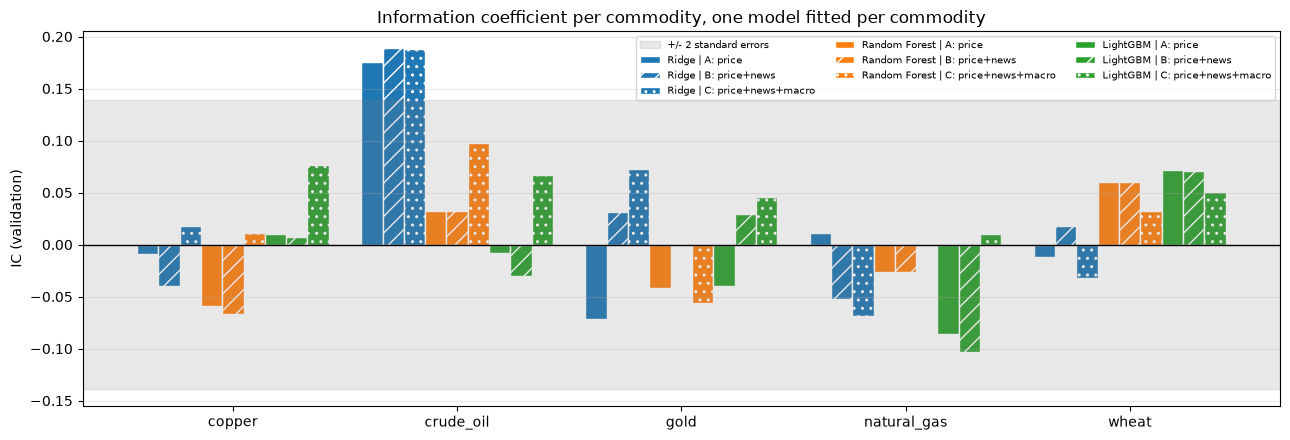

In [27]:
COLORS = {"Ridge": "C0", "Random Forest": "C1", "LightGBM": "C2"}
HATCH = {"A: price": "", "B: price+news": "//", "C: price+news+macro": ".."}
STYLES = {"A: price": "--", "B: price+news": "-", "C: price+news+macro": ":"}

fig, ax = plt.subplots(figsize=(13, 4.5))

x = np.arange(len(COMS))
width = 0.095
combos = [(m, f) for m in COLORS for f in HATCH]

for i, (mdl_name, fs_name) in enumerate(combos):

    values = [results.loc[(c, mdl_name, fs_name), "IC"] for c in COMS]

    ax.bar(x + (i - (len(combos) - 1) / 2) * width, values, width,
           color=COLORS[mdl_name], hatch=HATCH[fs_name],
           edgecolor="white", label=f"{mdl_name} | {fs_name}")

ax.axhline(0, color="k", lw=1)
ax.axhspan(-SE, SE, color="grey", alpha=0.18, label="+/- 2 standard errors")
ax.set_xticks(x)
ax.set_xticklabels(COMS)
ax.set_ylabel("IC (validation)")
ax.set_title("Information coefficient per commodity, one model fitted per commodity")
ax.legend(fontsize=7, ncol=3)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

**Diagnostic PnL per commodity — not a backtest.** A visual check of each signal on its own: position = sign of
the prediction, sized by its magnitude and capped at three times its average,

$$\text{pos}_t = \text{clip}\!\left(\frac{\hat r_t}{\tfrac{1}{t-1}\sum_{s<t}|\hat r_s|},\,-3,\,3\right),$$

where the scale uses only past predictions (expanding mean, lagged one week), so no future information enters the position

and PnL = cumulative $\text{pos}_t \times r_{t+1}$ over validation, gross of costs. No covariance, no costs,
no cross-section: this is the naive benchmark of the portfolio of §6. Black line = buy and hold.

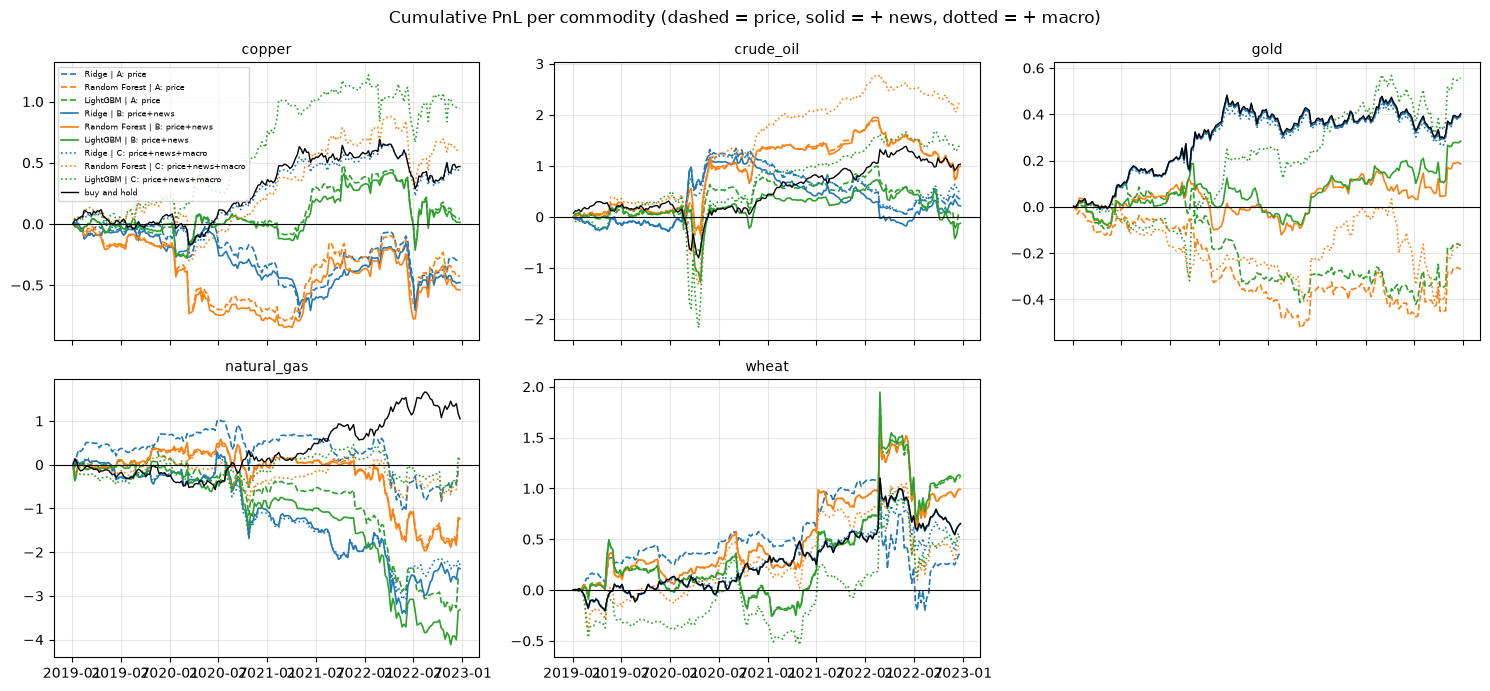

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for ax, com in zip(axes.ravel(), COMS):

    for (mdl_name, fs_name), A in ALPHA.items():

        # Position = sign of the prediction, sized by its magnitude (capped)
        scale = A[com].abs().expanding().mean().shift(1)
        pos = (A[com] / scale.where(scale > 1e-12)).clip(-3, 3).fillna(0)

        ax.plot(RET.index, (pos * RET[com]).cumsum(),
                color=COLORS[mdl_name], ls=STYLES[fs_name],
                lw=1.2, label=f"{mdl_name} | {fs_name}")

    ax.plot(RET.index, RET[com].cumsum(), color="k", lw=1, label="buy and hold")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(com, fontsize=10)
    ax.grid(alpha=0.3)

axes.ravel()[-1].axis("off")
axes.ravel()[0].legend(fontsize=6, loc="upper left")

fig.suptitle("Cumulative PnL per commodity "
             "(dashed = price, solid = + news, dotted = + macro)")
fig.tight_layout()
plt.show()


*Reading — where the signal comes from, by commodity.*
- **Crude oil:** Random Forest C (orange dotted) is the clear winner, ending around +2.2.
- **Natural gas:** nearly every model loses (LightGBM down to about −4) while buy and hold gains: the main drag.
- **Gold:** Ridge coincides with buy and hold (near-constant positive prediction); among the trees only LightGBM C
  ends positive.
- **Copper:** the two tree models on set C end clearly positive.
- **Wheat:** most configurations are positive, but the 2022 spike dominates.

This plot is **exploratory only**: no portfolio constraints, costs or leverage normalisation. The portfolio tests
below are the economic evaluation.

# 6. Portfolio construction: dynamic optimisation with transaction costs

The predicted returns $\alpha_t$ (one per commodity) are turned into positions $h_t$ by mean-variance
optimisation. Without costs, each week is solved in isolation (*static / myopic* optimiser):

$$h_t = \lambda V_t^{-1}\alpha_t ,$$

with $V_t$ the covariance of returns (rolling 52-week window) and $\lambda$ the risk tolerance. With a quadratic
trading cost $\tfrac12 (h_t - h_{t-1})^\top \Lambda_t (h_t - h_{t-1})$ the problem becomes **dynamic** — the
previous holdings enter the solution (Gârleanu & Pedersen, 2013; course chapter 30):

$$h_t = \left[\frac{V_t}{\lambda} + \Lambda_t\right]^{-1}(\alpha_t + \Lambda_t h_{t-1})
      = (I + \lambda V^{-1}\Lambda)^{-1}\lambda V^{-1}\alpha_t + \left[I - (I + \lambda V^{-1}\Lambda)^{-1}\right] h_{t-1}.$$

The optimal portfolio is a weighted average of the frictionless target and yesterday's portfolio: since the
target cannot be reached for free, the optimiser moves only part of the way towards it. This smooths positions
and lengthens holding periods.

**Tools — everything comes from `skfin`, nothing is reimplemented.**

| Import | Role |
|---|---|
| `skfin.estimators.MeanVariance`, `skfin.backtesting.Backtester` | course optimiser and walk-forward backtest |
| `skfin.backtesting_with_cost.MeanVarianceWithCost` | optimiser with quadratic costs |
| `skfin.backtesting_with_cost.BacktesterWithCost` | backtest that feeds $h_{t-1}$ forward at each step |
| `compute_pnl_components`, `average_holding_period` | gross / cost / net PnL; average holding period |
| `skfin.metrics.sharpe_ratio`, `skfin.plot.line` | annualised Sharpe, course plotting helper |

`sharpe_ratio` only auto-detects monthly and daily data, so weekly PnL is annualised explicitly with
`num_period_per_year=52`.

In [29]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from skfin.backtesting import Backtester
from skfin.estimators import MeanVariance
from skfin.metrics import sharpe_ratio
from skfin.plot import line, bar

from skfin.backtesting_with_cost import (
    BacktesterWithCost,
    MeanVarianceWithCost,
    average_holding_period,
    compute_pnl_components,
)

**Matrices passed to the backtester**, all `weeks × commodities`:

| Object | Content | Role |
|---|---|---|
| `ALPHA_FULL[key]` | predictions | input of the optimiser |
| `TARGET_FULL` | return of $t+1$ aligned on decision week $t$ | estimation of $V$ |
| `RET_REAL` | realised return of week $t$ | PnL: `h.shift(1) * ret` (the course's `pred_lag = 1`) |

`ALPHA` covers only validation, but the backtester needs 52 weeks of history to estimate $V$. `ALPHA_FULL`
therefore predicts the whole sample with the **same models, still fitted on the training set only**. The
predictions before the validation start are in-sample and serve only to fill the estimation windows: no position
is taken before `START`. The second cell builds `TARGET_FULL`, `RET_REAL` and the validation window.

In [30]:
# Predictions over the whole sample, to prime the backtester windows.
# The models are still fitted on the training set only.

ALPHA_FULL = {}

for fs_name in FEATURE_SETS:
    for mdl_name in make_models():
        ALPHA_FULL[(mdl_name, fs_name)] = pd.DataFrame(
            index=sorted(df["week"].unique()), columns=COMS, dtype=float
        )

for com in COMS:

    tr = train[train["commodity"] == com].sort_values("week")
    full = df[df["commodity"] == com].sort_values("week")

    for fs_name, feats in FEATURE_SETS.items():
        for mdl_name, mdl in make_models().items():

            pipe = mdl.fit(tr[feats], tr[TARGET])

            ALPHA_FULL[(mdl_name, fs_name)].loc[full["week"].values, com] = (
                pipe.predict(full[feats])
            )

print("Keys:", list(ALPHA_FULL))
print("Shape before dropna:",
      ALPHA_FULL[("Ridge", "C: price+news+macro")].shape)

ALPHA_FULL = {k: v.dropna() for k, v in ALPHA_FULL.items()}

print("Shape after dropna :",
      ALPHA_FULL[("Ridge", "C: price+news+macro")].shape)


Keys: [('Ridge', 'A: price'), ('Random Forest', 'A: price'), ('LightGBM', 'A: price'), ('Ridge', 'B: price+news'), ('Random Forest', 'B: price+news'), ('LightGBM', 'B: price+news'), ('Ridge', 'C: price+news+macro'), ('Random Forest', 'C: price+news+macro'), ('LightGBM', 'C: price+news+macro')]
Shape before dropna: (867, 5)
Shape after dropna : (867, 5)


In [31]:
# target: return of t+1 aligned on the decision week t (used to estimate V)
TARGET_FULL = df.pivot(index="week", columns="commodity", values="target").sort_index()

# ret: realised return of week t (used for the PnL)
RET_REAL = df.pivot(index="week", columns="commodity", values="ret").sort_index()

# Validation window: must match the split above and must NOT reach into the test
START = val["week"].min().strftime("%Y-%m-%d")
END = val["week"].max().strftime("%Y-%m-%d")

print("TARGET_FULL:", TARGET_FULL.shape, " RET_REAL:", RET_REAL.shape)
print("Validation window:", START, "->", END)

TARGET_FULL: (867, 5)  RET_REAL: (867, 5)
Validation window: 2019-01-04 -> 2022-12-23


**Cost-liquidity factor.** Following the course, $\Lambda_{n,t} = \frac{\gamma}{2}\cdot\frac{\sigma_{n,t}}{w_n}$
with $\sigma_{n,t}$ the 52-week volatility measured up to week $t-1$ (lagged one week, so the cost uses only past data), $w_n$ a liquidity weight and $\gamma$ a participation rate. With no
volume data for futures, the weights are equal, so commodities differ only through volatility (natural gas is
the most expensive to trade, gold the cheapest).

**Calibrating `GAMMA`.** The second cell runs the static backtest once (Ridge, set C) and, for four values of
$\gamma$, prints total cost / gross PnL. A ratio of 10–40 % is plausible; a ratio above 1 means costs exceed the
gross PnL and the optimiser would stop trading.

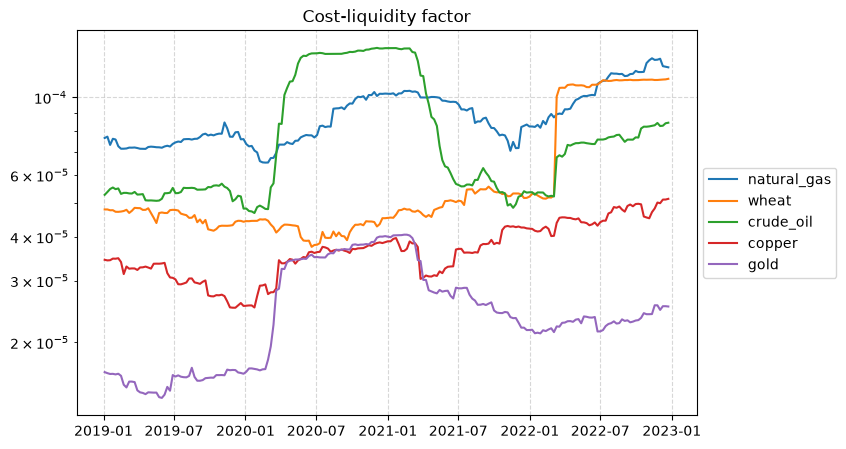

In [32]:
GAMMA = 1 / 2000
LIQ_W = pd.Series(1 / len(COMS), index=COMS)

vol_liquidity_factor = (
    0.5 * GAMMA * RET_REAL.rolling(52).std().shift(1).div(LIQ_W, axis=1)
).loc[:, COMS]

line(vol_liquidity_factor.loc[START:END], yscale="log",
     title="Cost-liquidity factor")


In [33]:
# Calibration of GAMMA: cumulative cost relative to gross PnL

MODELS = list(make_models())
KEY = (MODELS[0], "C: price+news+macro")   # Ridge on the full feature set

m_probe = BacktesterWithCost(
    MeanVarianceWithCost(),
    vol_liquidity_factor=None,
    max_train_size=52,
    test_size=1,
    start_date=START,
    end_date=END,
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

for g in [1/20, 1/200, 1/2000, 1/20000]:
    vlf = (0.5 * g * RET_REAL.rolling(52).std().shift(1).div(LIQ_W, axis=1)).loc[:, COMS]
    p = compute_pnl_components(m_probe.h_, RET_REAL, vol_liquidity_factor=vlf)
    ratio = -p["impact cost"].sum() / abs(p["gross"].sum())
    print(f"gamma = 1/{int(1/g):<6}  cost / gross = {ratio:8.2f}")


gamma = 1/20      cost / gross =     0.81
gamma = 1/200     cost / gross =     0.08
gamma = 1/2000    cost / gross =     0.01
gamma = 1/20000   cost / gross =     0.00


*Reading.* Cost is roughly linear in $\gamma$ for given positions: 0.81 at 1/20, 0.08 at 1/200, 0.01 at 1/2000,
≈ 0 at 1/20000. The value kept, **`GAMMA = 1/2000`, puts costs at about 1 % of the gross PnL**, well below the
10–40 % band: a cheap-trading scenario, which understates the role of the dynamic optimiser (1/200 would be closer
to the band). §8.1 shows what happens when costs are scaled up. This is an assumed cost model, not observed fees.

# 7. Backtest and results on the validation sample

## 7.1 Reference backtest: static mean-variance

Reference configuration `KEY` = Ridge on set C (the linear baseline on the richest set), fixed in advance to
study the mechanics of the optimiser. `BacktesterWithCost` with `vol_liquidity_factor=None` reproduces the
course's plain mean-variance backtest; the cost is then charged **after the fact** on those positions, to
measure what a strategy that ignores costs would really pay. Walk-forward: 52-week window for $V$, one-week
steps, positions from `START` to `END`.

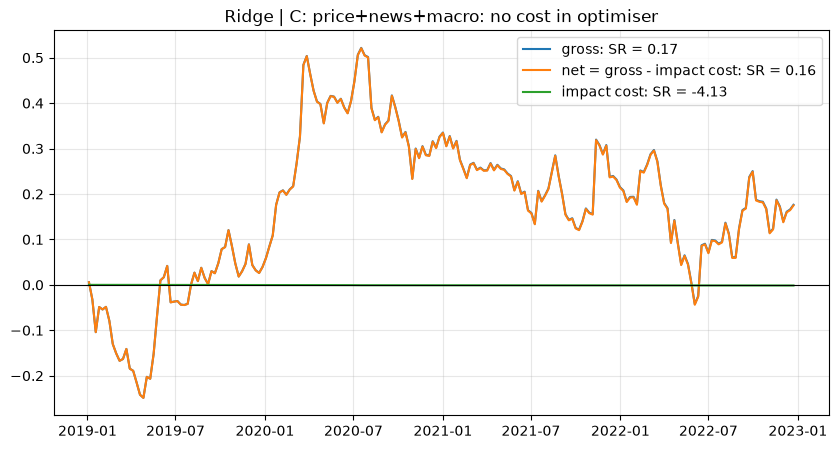

In [34]:
# Consistent annualized weekly Sharpe, with explicit date window.
def annual_sharpe(series, start, end):
    s = pd.Series(series).loc[start:end].dropna()
    if len(s) < 2 or s.std() < 1e-12:
        return np.nan
    return np.sqrt(52) * s.mean() / s.std()

BT_KW = dict(max_train_size=52, test_size=1, start_date=START, end_date=END)

m0 = BacktesterWithCost(
    MeanVarianceWithCost(), vol_liquidity_factor=None, **BT_KW
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

pnlc = compute_pnl_components(
    m0.h_, RET_REAL, vol_liquidity_factor=vol_liquidity_factor
)

pnl_static_df = pd.DataFrame(pnlc).loc[START:END]
fig, ax = plt.subplots(figsize=(10, 5))
for k in ["gross", "net = gross - impact cost", "impact cost"]:
    s = pnl_static_df[k]
    sr = annual_sharpe(s, START, END)
    lbl = k if pd.isna(sr) else f"{k}: SR = {sr:.2f}"
    ax.plot(s.index, s.cumsum(), label=lbl)
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"{KEY[0]} | {KEY[1]}: no cost in optimiser")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


*Reading.* Gross Sharpe 0.17 and net Sharpe 0.16: the impact cost line is flat (costs ≈ 1 % of gross). The PnL
peaks around +0.52 in mid-2020, then gives most of it back in 2021–2022 and ends near +0.18. Ridge C is a weak
signal: this backtest serves to study the cost mechanics, not as a performance result.

## 7.2 Dynamic optimisation with quadratic costs

Same predictions, but the cost now enters the optimiser, which receives $h_{t-1}$ at each step. The three cells:
the PnL components of the dynamic backtest, the two net PnLs on one chart, and the average holding periods.

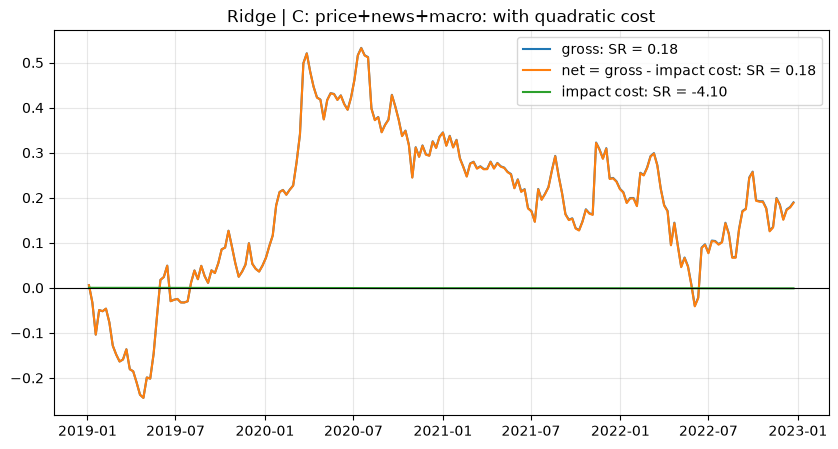

In [35]:
m = BacktesterWithCost(
    MeanVarianceWithCost(), vol_liquidity_factor,
    return_pnl_component=True, **BT_KW
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

bt_static = m0
bt_dyn = m

pnl_dynamic_df = pd.DataFrame(bt_dyn.pnl_).loc[START:END]
fig, ax = plt.subplots(figsize=(10, 5))
for k in ["gross", "net = gross - impact cost", "impact cost"]:
    s = pnl_dynamic_df[k]
    sr = annual_sharpe(s, START, END)
    lbl = k if pd.isna(sr) else f"{k}: SR = {sr:.2f}"
    ax.plot(s.index, s.cumsum(), label=lbl)
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"{KEY[0]} | {KEY[1]}: with quadratic cost")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


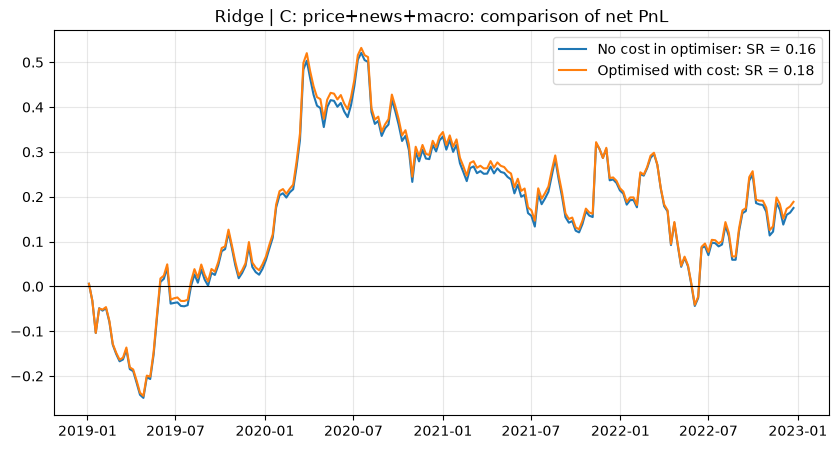

In [36]:
net_label = "net = gross - impact cost"
comparison = pd.DataFrame({
    "No cost in optimiser": pnlc[net_label],
    "Optimised with cost": bt_dyn.pnl_[net_label]
}).loc[START:END]
fig, ax = plt.subplots(figsize=(10, 5))
for col in comparison.columns:
    s = comparison[col]
    sr = annual_sharpe(s, START, END)
    ax.plot(s.index, s.cumsum(), label=f"{col}: SR = {sr:.2f}")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"{KEY[0]} | {KEY[1]}: comparison of net PnL")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


In [37]:
print(
    f"Average holding period (weeks):"
    f"\n - no cost in the optimiser    = {average_holding_period(bt_static.h_):.1f}"
    f"\n - optimised with quadratic cost = {average_holding_period(bt_dyn.h_):.1f}"
)

Average holding period (weeks):
 - no cost in the optimiser    = 5.6
 - optimised with quadratic cost = 6.3


*Reading.* Net Sharpe 0.165 (static) → 0.178 (dynamic); average holding period 5.6 → 6.3 weeks. The dynamic
optimiser trades less and earns slightly more, but at this cost level the two curves are almost the same.

## 7.3 The nine prediction sets through both optimisers

Same constraints, risk model, windows and cost: differences come only from the predictions and from whether the
cost is inside the optimiser. For each (model, feature set): gross and net Sharpe, and holding period.

In [38]:
# Compare 3 models x 3 feature sets x 2 optimisers, all on validation
rows, H = [], {}
for key, alpha in ALPHA_FULL.items():
    bt0 = BacktesterWithCost(
        MeanVarianceWithCost(), vol_liquidity_factor=None, **BT_KW
    ).train(alpha, TARGET_FULL, RET_REAL)
    bt1 = BacktesterWithCost(
        MeanVarianceWithCost(), vol_liquidity_factor,
        return_pnl_component=True, **BT_KW
    ).train(alpha, TARGET_FULL, RET_REAL)
    p0 = compute_pnl_components(bt0.h_, RET_REAL,
                                vol_liquidity_factor=vol_liquidity_factor)
    p1 = bt1.pnl_
    H[(key, "static")] = bt0.h_
    H[(key, "dynamic")] = bt1.h_
    for label, p, h in [("static", p0, bt0.h_), ("dynamic", p1, bt1.h_)]:
        rows.append({
            "model": key[0], "features": key[1], "optimiser": label,
            "sr gross": annual_sharpe(p["gross"], START, END),
            "sr net": annual_sharpe(p[net_label], START, END),
            "holding": average_holding_period(h)
        })
portfolio_results = (pd.DataFrame(rows)
                     .set_index(["model", "features", "optimiser"])
                     .sort_index())
display(portfolio_results.round(3))


sr gross  sr net  holding
model         features            optimiser                           
LightGBM      A: price            dynamic       0.358   0.257    2.050
                                  static        0.353   0.222    1.886
              B: price+news       dynamic       0.352   0.253    2.094
                                  static        0.356   0.227    1.923
              C: price+news+macro dynamic       0.801   0.731    2.780
                                  static        0.806   0.716    2.517
Random Forest A: price            dynamic       0.515   0.427    1.937
                                  static        0.529   0.414    1.809
              B: price+news       dynamic       0.647   0.559    2.001
                                  static        0.663   0.547    1.846
              C: price+news+macro dynamic       0.764   0.715    2.702
                                  static        0.786   0.721    2.423
Ridge         A: price            dynamic       0.864   0.846    3.412
                                  static        0.869   0.846    3.035
              B: price+news       dynamic      -0.032  -0.056    2.992
                                  static       -0.063  -0.097    2.604
              C: price+news+macro dynamic       0.179   0.178    6.316
                                  static        0.166   0.165    5.576

*Reading.*
- **Tree models improve with macro.** LightGBM: 0.26 → 0.25 → 0.73 (dynamic, A → B → C); Random Forest:
  0.43 → 0.56 → 0.715 — the only model that improves at each step.
- **Ridge is best with prices only** (0.846, both optimisers), collapses with news (−0.06) and partly recovers with
  macro (0.18).
- The best validation net Sharpe is therefore **Ridge A (0.846)**, ahead of LightGBM C (0.731) and Random Forest
  C (0.715 dynamic / 0.721 static). The model selected in §9 is **not** the best validation strategy (see §9.1).
- Costs take 0.001 to 0.13 off the Sharpe, more for the fast-trading tree models (holding ≈ 2–2.8 weeks against
  3–6 for Ridge).

**What the dynamic optimiser adds, holding predictions fixed** (dynamic − static, net Sharpe and holding).

In [39]:
# What the dynamic optimiser adds, holding the predictions fixed

w = portfolio_results.reset_index().pivot_table(
    index=["model", "features"], columns="optimiser",
    values=["sr net", "holding"])

gain_dyn = pd.DataFrame({
    "sr net static": w[("sr net", "static")],
    "sr net dynamic": w[("sr net", "dynamic")],
    "difference": w[("sr net", "dynamic")] - w[("sr net", "static")],
    "holding static": w[("holding", "static")],
    "holding dynamic": w[("holding", "dynamic")],
})

display(gain_dyn.round(3))

sr net static  sr net dynamic  difference  \
model         features                                                         
LightGBM      A: price                     0.222           0.257       0.034   
              B: price+news                0.227           0.253       0.025   
              C: price+news+macro          0.716           0.731       0.015   
Random Forest A: price                     0.414           0.427       0.013   
              B: price+news                0.547           0.559       0.012   
              C: price+news+macro          0.721           0.715      -0.006   
Ridge         A: price                     0.846           0.846       0.000   
              B: price+news               -0.097          -0.056       0.041   
              C: price+news+macro          0.165           0.178       0.014   

                                   holding static  holding dynamic  
model         features                                              
LightGBM      A: price                      1.886            2.050  
              B: price+news                 1.923            2.094  
              C: price+news+macro           2.517            2.780  
Random Forest A: price                      1.809            1.937  
              B: price+news                 1.846            2.001  
              C: price+news+macro           2.423            2.702  
Ridge         A: price                      3.035            3.412  
              B: price+news                 2.604            2.992  
              C: price+news+macro           5.576            6.316

*Reading.* Net Sharpe is higher with the dynamic optimiser in **7 of 9** configurations (gains up to +0.041),
unchanged for Ridge A (0.846 in both cases) and slightly lower for Random Forest C (−0.006). Holding periods are
longer in all nine (+0.13 to +0.74 weeks). Consistent with H3, but small at this cost level.

**Attribution by feature block at the portfolio level:** net Sharpe per feature set, news gain (B − A) and macro
gain (C − B).

In [40]:
# What each feature block adds at the portfolio level, by model and optimiser

net_by_set = portfolio_results["sr net"].unstack("features")

display(pd.DataFrame({
    "A: price": net_by_set["A: price"],
    "B: price+news": net_by_set["B: price+news"],
    "C: price+news+macro": net_by_set["C: price+news+macro"],
    "news (B - A)": net_by_set["B: price+news"] - net_by_set["A: price"],
    "macro (C - B)": net_by_set["C: price+news+macro"] - net_by_set["B: price+news"],
}).round(3))

A: price  B: price+news  C: price+news+macro  \
model         optimiser                                                 
LightGBM      dynamic       0.257          0.253                0.731   
              static        0.222          0.227                0.716   
Random Forest dynamic       0.427          0.559                0.715   
              static        0.414          0.547                0.721   
Ridge         dynamic       0.846         -0.056                0.178   
              static        0.846         -0.097                0.165   

                         news (B - A)  macro (C - B)  
model         optimiser                               
LightGBM      dynamic          -0.004          0.478  
              static            0.005          0.488  
Random Forest dynamic           0.131          0.157  
              static            0.133          0.174  
Ridge         dynamic          -0.902          0.234  
              static           -0.943          0.262

*Reading.* **Macro (C − B)** adds the most, for every model: +0.48 (LightGBM), +0.16 (Random Forest), +0.23 (Ridge)
with the dynamic optimiser, similar with the static one. **News (B − A)** helps only Random Forest (+0.13); it is
neutral for LightGBM (−0.004) and very negative for Ridge (−0.90). Even for Ridge, C (0.18) stays far below
price-only A (0.85): with ~460 observations per commodity, the linear model cannot use 14 noisy features. All
these gains are below one standard error of a Sharpe ratio (≈ 0.5, §8.5).

# 8. Robustness

Four questions: does the dynamic optimiser behave as theory predicts when costs change (8.1–8.3)? Is the data
pipeline sound and is the relationship stable over time (8.4)? Are the validation Sharpe ratios distinguishable
from zero (8.5)?

## 8.1 Sensitivity to the cost level

Hypothesis: the gap between dynamic and static optimisers **widens as costs rise** and vanishes at zero cost.
The second half is also a correctness check: at zero cost the two solutions must coincide. The reference
configuration is re-run with the cost-liquidity factor multiplied by 0, 0.25, …, 4 (4× ≈ `GAMMA` = 1/500,
costs ≈ 4 % of gross PnL).

In [41]:
# Transaction cost sensitivity for the Ridge C reference strategy
SCALES = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]
rows = []
for s in SCALES:
    vlf_s = vol_liquidity_factor * s
    if s == 0:
        p_zero = compute_pnl_components(bt_static.h_, RET_REAL)
        sr_dyn = annual_sharpe(p_zero, START, END)
        hp_dyn = average_holding_period(bt_static.h_)
        sr_stat, hp_stat = sr_dyn, hp_dyn
    else:
        bt = BacktesterWithCost(
            MeanVarianceWithCost(), vlf_s,
            return_pnl_component=True, **BT_KW
        ).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)
        p_stat = compute_pnl_components(
            bt_static.h_, RET_REAL, vol_liquidity_factor=vlf_s
        )
        sr_stat = annual_sharpe(p_stat[net_label], START, END)
        hp_stat = average_holding_period(bt_static.h_)
        sr_dyn = annual_sharpe(bt.pnl_[net_label], START, END)
        hp_dyn = average_holding_period(bt.h_)
    rows.append({"cost": s, "sr net static": sr_stat,
                 "sr net dynamic": sr_dyn,
                 "holding static": hp_stat, "holding dynamic": hp_dyn})
sensi = pd.DataFrame(rows).set_index("cost")
display(sensi.round(3))


,sr net static,sr net dynamic,holding static,holding dynamic
cost,,,,
0.00,0.166,0.166,5.576,5.576
0.25,0.166,0.168,5.576,5.772
0.50,0.165,0.171,5.576,5.961
1.00,0.165,0.178,5.576,6.316
2.00,0.163,0.194,5.576,6.963
4.00,0.161,0.227,5.576,8.102


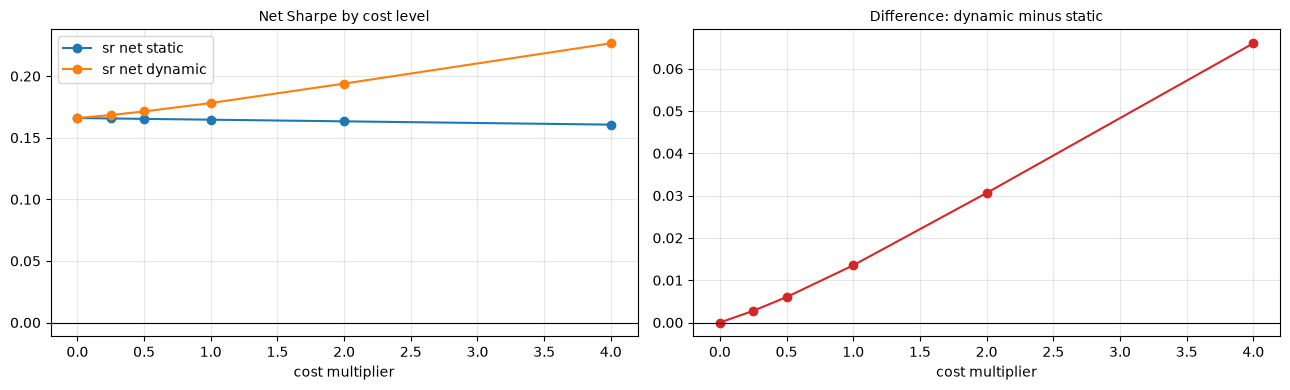

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sensi[["sr net static", "sr net dynamic"]].plot(ax=ax[0], marker="o")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Net Sharpe by cost level", fontsize=10)
ax[0].set_xlabel("cost multiplier")
ax[0].grid(alpha=0.3)

(sensi["sr net dynamic"] - sensi["sr net static"]).plot(
    ax=ax[1], marker="o", color="C3")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Difference: dynamic minus static", fontsize=10)
ax[1].set_xlabel("cost multiplier")
ax[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

*Reading.* At zero cost the two optimisers coincide (check passed). The gap then grows monotonically: +0.002 at
0.25×, +0.013 at 1×, +0.031 at 2×, **+0.066 at 4×**. The static net Sharpe slowly falls (0.166 → 0.161) while the
dynamic one *rises* (0.166 → 0.227), and the dynamic holding period lengthens from 5.6 to 8.1 weeks: trading more
slowly averages noisy forecasts over several weeks, so the cost term also acts as a regulariser on a weak signal.
This is a sensitivity to assumed costs, not evidence that higher real costs are beneficial.

## 8.2 Holding period and liquidity, commodity by commodity

Expected: the more expensive a commodity is to trade, the more the optimiser should lengthen its holding period.
x-axis: average cost-liquidity factor; y-axis: relative change of holding period, dynamic vs static.

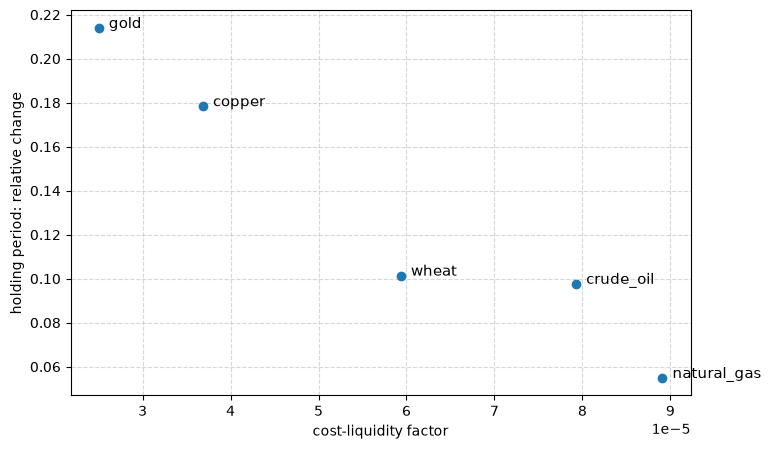

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.set_axisbelow(True)
ax.grid(True, linestyle="--", alpha=0.5)

avp = (
    pd.Series({c: average_holding_period(bt_dyn.h_[c]) for c in bt_static.h_.columns})
    .div(pd.Series({c: average_holding_period(bt_static.h_[c])
                    for c in bt_static.h_.columns}))
    .sub(1)
)

scatter_df = pd.concat(
    {
        "cost-liquidity factor": vol_liquidity_factor.loc[START:END].mean(),
        "holding period: relative change": avp,
    },
    axis=1,
)

ax.scatter(scatter_df.iloc[:, 0].values, scatter_df.iloc[:, 1].values)
ax.set_xlabel(scatter_df.columns[0])
ax.set_ylabel(scatter_df.columns[1])

for i, txt in enumerate(scatter_df.index):
    ax.text(scatter_df.iloc[i, 0], scatter_df.iloc[i, 1], "  " + txt, fontsize=11)

plt.show()


*Reading.* All five holding periods lengthen, but the ordering is the **opposite** of the expectation: gold, the
cheapest to trade, lengthens most (+21 %), then copper (+18 %), wheat and crude oil (+10 %), and natural gas, the
most expensive, least (+5.5 %). The closed form explains it. For one asset, the weight on yesterday's position is
$\Lambda / (\sigma^2/\lambda + \Lambda)$; with $\Lambda \propto \sigma$ it becomes $c / (\sigma/\lambda + c)$, which
*decreases* with $\sigma$. Relative to its risk, a volatile contract is cheap to trade, so it is smoothed less. With
equal liquidity weights volatility drives both cost and risk; real volumes would be needed to separate them.
(Five points: descriptive only.)

## 8.3 Positions: static vs dynamic

Positions of the two optimisers on two commodities, with their correlation. Theory: the dynamic curve is a
smoothed version of the static one (an exponential average of past targets).

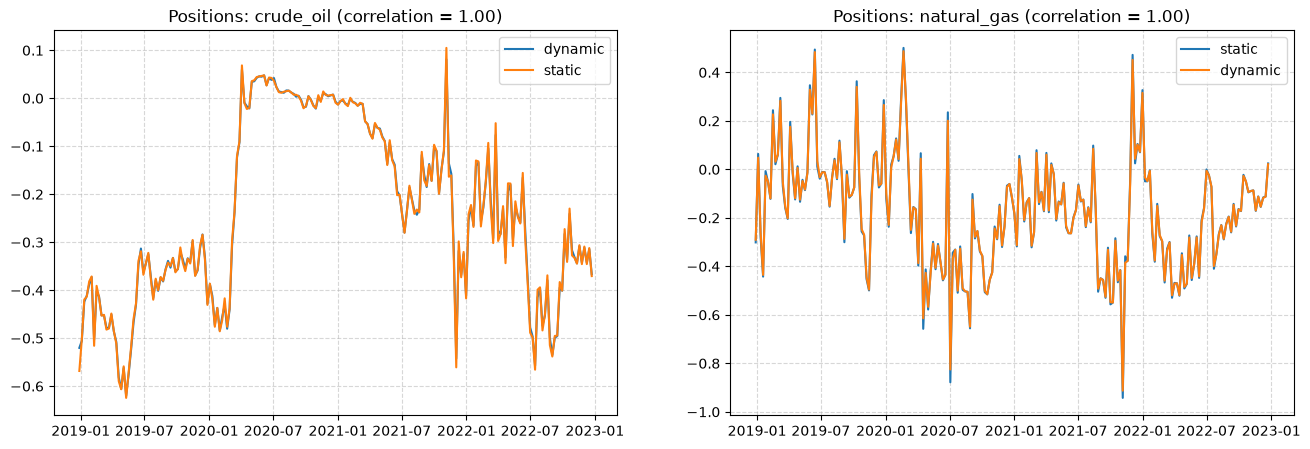

In [44]:
sample = ["crude_oil", "natural_gas"]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

for i, com in enumerate(sample):
    holdings_df = pd.concat(
        {"static": bt_static.h_[com], "dynamic": bt_dyn.h_[com]}, axis=1
    )
    line(
        holdings_df,
        title=f"Positions: {com} (correlation ={holdings_df.corr().iloc[0, 1]: .2f})",
        ax=ax[i],
        loc="best",
    )

*Reading.* Correlation 1.00 for both commodities: at the calibrated cost (≈ 1 % of gross PnL) the smoothing is
barely visible. The dynamic optimiser matters only at higher cost levels (§8.1).

## 8.4 Integrity checks

These produce no strategy result; they say whether the results above can be interpreted at all.

1. **Target alignment and split.** `target` must be exactly next week's `ret` (a sign or off-by-one error would
   invert everything), and the weeks between samples are counted.
2. **Regime break, without any model.** The correlation of each feature with the target, computed separately on
   training and validation. A sign change means the relationship reversed between the two periods — which would
   produce backwards predictions with no model at fault.

In [45]:
chk = df.sort_values(["commodity", "week"]).copy()
chk["ret_next"] = chk.groupby("commodity")["ret"].shift(-1)

gap = (chk["target"] - chk["ret_next"]).abs().max()
print(f"Largest gap between target and lagged ret: {gap:.2e}   (expected ~ 0)")

print("\nTrain      :", train["week"].min().date(), "->", train["week"].max().date())
print("Validation :", val["week"].min().date(), "->", val["week"].max().date())
print("Test       :", test["week"].min().date(), "->", test["week"].max().date())

unused = df[(df["week"] > train["week"].max()) & (df["week"] < val["week"].min())]
print("\nWeeks used by neither train nor validation:", unused["week"].nunique())

Largest gap between target and lagged ret: 0.00e+00   (expected ~ 0)

Train      : 2010-02-12 -> 2018-12-21
Validation : 2019-01-04 -> 2022-12-23
Test       : 2023-01-06 -> 2026-09-18

Weeks used by neither train nor validation: 1


In [46]:
VARS = PRICE + NEWS + MACRO

ic_periods = {}

for name, d in [("train", train), ("validation", val)]:
    ic_periods[name] = d.groupby("commodity").apply(
        lambda g: pd.Series({v: g[v].corr(g[TARGET]) for v in VARS}),
        include_groups=False
    )

ic_cmp = pd.concat(ic_periods, axis=1)
display(ic_cmp.round(3))

# Features whose sign flips between the two periods
flip = (np.sign(ic_periods["train"]) != np.sign(ic_periods["validation"]))
print("Share of (commodity, feature) pairs whose IC changes sign:",
      f"{100 * flip.values.mean():.0f} %")

print("\nBy feature block:")
for block_name, block in [("price", PRICE), ("news", NEWS), ("macro", MACRO)]:
    print(f"  {block_name:6s} {100 * flip[block].values.mean():5.0f} %")

train                                                      \
               ret mom_4w mom_12w vol_12w net_tone n_relevant has_news   
commodity                                                                
copper      -0.065 -0.071  -0.059   0.054    0.071      0.014    0.006   
crude_oil    0.102  0.051   0.035   0.130    0.039     -0.023   -0.029   
gold         0.057 -0.023  -0.025  -0.015   -0.009     -0.016   -0.060   
natural_gas -0.037 -0.077  -0.086  -0.058    0.070     -0.031   -0.051   
wheat        0.020 -0.038  -0.080   0.067    0.014     -0.012    0.014   

                                                               ... validation  \
            attention macro_fed_funds_rate macro_us_10y_yield  ...   net_tone   
commodity                                                      ...              
copper          0.012                0.004             -0.011  ...      0.014   
crude_oil      -0.025               -0.018             -0.041  ...      0.032   
gold           -0.047                0.005              0.106  ...      0.007   
natural_gas    -0.052                0.032             -0.024  ...     -0.120   
wheat          -0.003                0.022              0.040  ...     -0.091   

                                                                \
            n_relevant has_news attention macro_fed_funds_rate   
commodity                                                        
copper          -0.175   -0.116    -0.167               -0.076   
crude_oil       -0.053   -0.043    -0.054               -0.128   
gold            -0.034   -0.047    -0.064                0.036   
natural_gas      0.009    0.050     0.042               -0.156   
wheat           -0.023   -0.038    -0.004               -0.070   

                                                         \
            macro_us_10y_yield macro_yield_curve_10y_2y   
commodity                                                 
copper                  -0.112                    0.055   
crude_oil               -0.076                    0.090   
gold                    -0.016                   -0.020   
natural_gas             -0.107                    0.098   
wheat                   -0.075                    0.046   

                                                                              
            macro_dollar_return_4w macro_vix macro_inflation_expectation_10y  
commodity                                                                     
copper                       0.002     0.067                          -0.118  
crude_oil                   -0.086     0.049                          -0.049  
gold                        -0.024     0.075                          -0.131  
natural_gas                  0.068     0.046                           0.039  
wheat                       -0.003    -0.005                           0.007  

[5 rows x 28 columns]

Share of (commodity, feature) pairs whose IC changes sign: 43 %

By feature block:
  price     45 %
  news      50 %
  macro     37 %


*Reading.* The target is exactly the next week's return (gap 0), and one week is purged between train and
validation. But **43 % of the (commodity, feature) correlations change sign** between 2010–2018 and 2019–2022:
50 % for news — a coin flip — 45 % for prices and 37 % for macro, the most stable block. Many correlations are
below 0.1 in absolute value, so part of this is noise, but the relationships learnt on 2010–2018 cannot be
expected to hold reliably later, especially for news.

## 8.5 Significance of the validation results

A Sharpe ratio is meaningless without its standard error. Lo (2002): $\text{se}(\widehat{SR}) \approx
\sqrt{(1 + SR^2/2)/T}$ with $T$ in years — about 0.5 over four years, so a Sharpe of 0.3 is not distinguishable
from zero. The second cell asks whether the PnL is steady or carried by a single year.

Multiple testing must also be declared: nine prediction sets, two optimisers, four values of `GAMMA` and six cost
multipliers — about thirty configurations. With that many trials an apparently good Sharpe can arise by chance;
Harvey, Liu & Zhu (2016) recommend $t > 3$ in such cases.

In [47]:
# Approximate standard error (assumes independent weekly PnL)
def sharpe_se(pnl, start=START, end=END, periods=52):
    series = pd.Series(pnl).loc[start:end].dropna()
    sr = annual_sharpe(series, start, end)
    T = len(series) / periods
    return np.sqrt((1 + 0.5 * sr**2) / T) if T > 0 else np.nan

def drawdown_max(pnl):
    c = pd.Series(pnl).cumsum()
    return (c - c.cummax()).min()

for lab, p in [("static", pnlc[net_label]),
               ("dynamic", bt_dyn.pnl_[net_label])]:
    s = pd.Series(p).loc[START:END]
    sr = annual_sharpe(s, START, END)
    se = sharpe_se(s)
    print(f"{lab:8s}  net Sharpe = {sr:6.3f}   s.e. = {se:5.3f}   "
          f"t = {sr / se:5.2f}   max DD = {drawdown_max(s):6.2f}")


static    net Sharpe =  0.165   s.e. = 0.503   t =  0.33   max DD =  -0.56
dynamic   net Sharpe =  0.178   s.e. = 0.504   t =  0.35   max DD =  -0.57


In [48]:
# Annual gross PnL for Ridge C reference (validation only)
p = pd.Series(pnlc["gross"]).loc[START:END]
print("Gross Sharpe by year:")
for year, g in p.groupby(p.index.year):
    print(f"  {year} : pnl = {g.sum():7.3f}   "
          f"sr = {annual_sharpe(g, str(year), str(year)):6.2f}   "
          f"({len(g)} weeks)")
print("\nShare of the best year in total PnL:",
      round(p.groupby(p.index.year).sum().max() / p.sum(), 2))


Gross Sharpe by year:
  2019 : pnl =   0.040   sr =   0.16   (52 weeks)
  2020 : pnl =   0.287   sr =   0.97   (52 weeks)
  2021 : pnl =  -0.111   sr =  -0.44   (53 weeks)
  2022 : pnl =  -0.039   sr =  -0.14   (51 weeks)

Share of the best year in total PnL: 1.63


*Reading.* Ridge C reference: net Sharpe 0.165 (static) and 0.178 (dynamic), $t \approx 0.33$ and $0.35$, maximum
drawdown ≈ −0.56 (PnL units of the optimiser's positions, not % of capital). Gross PnL by year: +0.040 (2019),
+0.287 (2020), −0.111 (2021), −0.039 (2022). The best year, 2020, represents 163 % of the total gross PnL: without
it the strategy loses money — a strongly concentrated result.

## 8.6 Assumptions behind all portfolio results

- Quadratic costs ($\beta = 1$): more conservative than the square-root law documented by Frazzini, Israel &
  Moskowitz (2018), but with a closed-form solution.
- Liquidity proxied by volatility alone, for lack of volume data; covariance on a rolling 52-week window, without
  shrinkage.
- Forecasting models fitted once on the training set, not refitted in each window; all nine prediction sets are
  treated identically, so comparisons between them remain valid.
- In-sample predictions before `START` are used only to fill estimation windows.
- Macro data from FRED's current vintage, lagged one week.

# 9. Frozen specification and out-of-sample test

## 9.1 Frozen specification

Chosen from the validation results only, before looking at the test sample; nothing below is revised afterwards.

| Choice | Value | Reason |
|---|---|---|
| Feature set | C: price+news+macro | the only set that improves both tree models (IC and net Sharpe), and the full information set the question is about |
| Model | Random Forest | Random Forest C and LightGBM C are statistically indistinguishable (dynamic net Sharpe 0.715 vs 0.731, s.e. ≈ 0.56). Bagging has fewer interacting settings than boosting (no learning-rate / number-of-rounds trade-off), so its validation score is less likely to reflect lucky settings; it is also the only model that improves at each step A → B → C. Ridge A (0.846) has the best validation Sharpe, but it is a price-only benchmark that does not answer the research question, and Ridge collapses as soon as features are added. This choice does not make Random Forest C the best validation model |
| Optimiser | dynamic | better in 7 of 9 configurations, never worse by more than 0.006, and its advantage grows with costs (§8.1) |
| `GAMMA` | 1/2000 | calibrated in §6 |
| `max_train_size` | 52 weeks | covariance window |

## 9.2 Test run

The test is run **once**, with no tuning, and reported as it comes. Nothing is refitted: the models are already
trained, and `ALPHA_FULL` covers the whole period; only the window moves to 2023-01 → 2026-09. The first cell
fixes the specification and checks that predictions and the cost factor cover the test window; the second runs
the static and dynamic backtests.

In [49]:
# Frozen specification, chosen from the validation results
KEY_FINAL = ("Random Forest", "C: price+news+macro")
FINAL_OPTIMISER = "dynamic"          # "static" or "dynamic"

START_TEST = test["week"].min().strftime("%Y-%m-%d")
END_TEST = test["week"].max().strftime("%Y-%m-%d")

# Coverage check before running anything
print("ALPHA_FULL           :", ALPHA_FULL[KEY_FINAL].index.min().date(),
      "->", ALPHA_FULL[KEY_FINAL].index.max().date())
print("vol_liquidity_factor :", vol_liquidity_factor.dropna().index.min().date(),
      "->", vol_liquidity_factor.dropna().index.max().date())
print("Test window          :", START_TEST, "->", END_TEST)
print("Test weeks available :",
      ALPHA_FULL[KEY_FINAL].loc[START_TEST:END_TEST].shape[0])

ALPHA_FULL           : 2010-02-12 -> 2026-09-18
vol_liquidity_factor : 2011-02-11 -> 2026-09-18
Test window          : 2023-01-06 -> 2026-09-18
Test weeks available : 194


In [50]:
BT_TEST = dict(max_train_size=52, test_size=1,
               start_date=START_TEST, end_date=END_TEST)

# Static: cost applied after the fact to the positions
bt_static_test = BacktesterWithCost(
    MeanVarianceWithCost(), vol_liquidity_factor=None, **BT_TEST
).train(ALPHA_FULL[KEY_FINAL], TARGET_FULL, RET_REAL)

pnlc_test = compute_pnl_components(
    bt_static_test.h_, RET_REAL, vol_liquidity_factor=vol_liquidity_factor
)

# Dynamic: cost inside the optimiser
bt_dyn_test = BacktesterWithCost(
    MeanVarianceWithCost(), vol_liquidity_factor,
    return_pnl_component=True, **BT_TEST
).train(ALPHA_FULL[KEY_FINAL], TARGET_FULL, RET_REAL)

print("Test positions:", bt_dyn_test.h_.index.min().date(),
      "->", bt_dyn_test.h_.index.max().date(),
      f"({len(bt_dyn_test.h_)} weeks)")

Test positions: 2022-12-30 -> 2026-09-18 (195 weeks)


## 9.3 Validation against test

All four columns below report the **same frozen Random Forest C specification**, evaluated with static versus dynamic optimisation in 2019–2022 validation and 2023–2026 held-out test. Sharpe ratios are annualised with 52 weeks/year; initial warm-up weeks are excluded from the summary. These are additive PnL drawdowns, not percentage drawdowns of capital.


In [51]:
# Fair validation/test comparison: SAME frozen model in both periods
h_val_static = H[(KEY_FINAL, "static")]
h_val_dynamic = H[(KEY_FINAL, "dynamic")]

pnl_val_static = compute_pnl_components(
    h_val_static, RET_REAL, vol_liquidity_factor=vol_liquidity_factor
)
pnl_val_dynamic = compute_pnl_components(
    h_val_dynamic, RET_REAL, vol_liquidity_factor=vol_liquidity_factor
)

def summarise(p, h, start, end):
    gross = pd.Series(p["gross"]).loc[start:end].dropna()
    net = pd.Series(p[net_label]).loc[start:end].dropna()
    sr = annual_sharpe(net, start, end)
    se = sharpe_se(net, start, end)
    return {
        "Sharpe gross": annual_sharpe(gross, start, end),
        "Sharpe net": sr,
        "Sharpe s.e.": se,
        "t-statistic": sr / se,
        "max DD": drawdown_max(net),
        "holding (weeks)": average_holding_period(h.loc[start:end]),
        "weeks": len(net)
    }

summary = pd.DataFrame({
    "validation static": summarise(pnl_val_static, h_val_static, START, END),
    "validation dynamic": summarise(pnl_val_dynamic, h_val_dynamic, START, END),
    "test static": summarise(pnlc_test, bt_static_test.h_, START_TEST, END_TEST),
    "test dynamic": summarise(bt_dyn_test.pnl_, bt_dyn_test.h_, START_TEST, END_TEST)
})
display(summary.round(3))


,validation static,validation dynamic,test static,test dynamic
Sharpe gross,0.786,0.764,0.586,0.636
Sharpe net,0.721,0.715,0.531,0.595
Sharpe s.e.,0.561,0.560,0.553,0.562
t-statistic,1.285,1.277,0.960,1.059
max DD,-4.337,-4.177,-1.840,-1.669
holding (weeks),2.422,2.701,2.249,2.472
weeks,208.000,208.000,194.000,194.000


*Reading.* The validation columns match the §7.3 table (0.721 static / 0.715 dynamic). On the test sample the
frozen specification earns a **net Sharpe of 0.531 (static) and 0.595 (dynamic)**: a decay of −0.12 for the
dynamic version, well within one standard error (≈ 0.56). The dynamic optimiser again beats the static one
(+0.064), with a smaller drawdown (−1.67 vs −1.84) and longer holding (2.5 vs 2.2 weeks); costs take only about
0.05 off the Sharpe. But $t = 1.06$ (dynamic) and $0.96$ (static): far from 2, and from the $t > 3$ recommended
after ~30 trials. Drawdowns are additive PnL in position units, not percentages of capital.

**Cumulative net PnL.** Both panels below display the same frozen **Random Forest C** model: the left panel is 2019–2022 validation; the right panel is 2023–2026 test. Initialisation weeks are excluded.


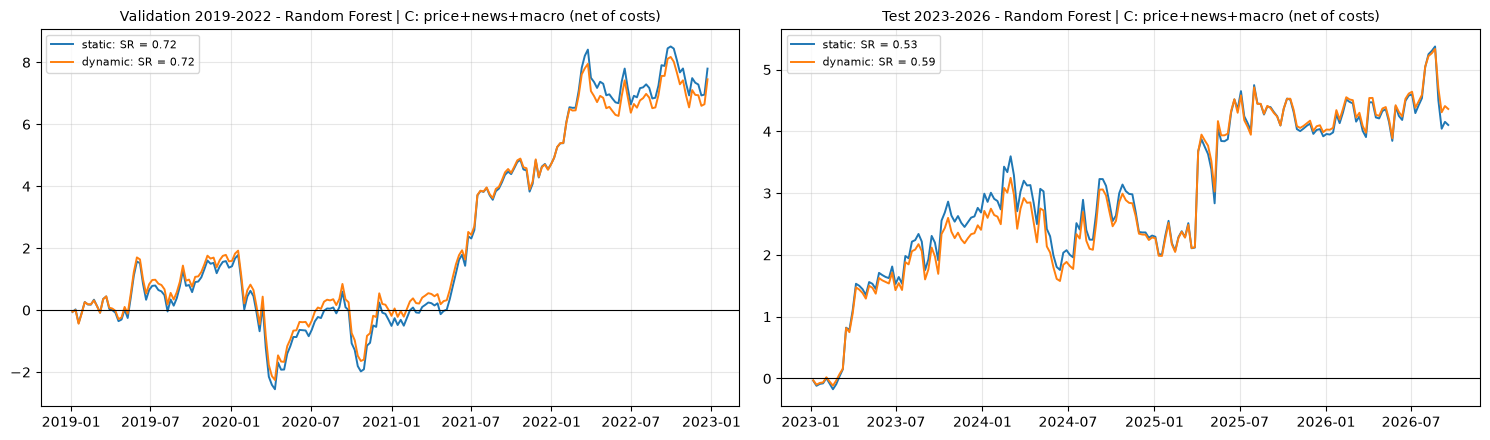

In [52]:
# Same frozen Random Forest C model in both panels; net PnL
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
net_label = "net = gross - impact cost"
panels = [
    (f"Validation {START[:4]}-{END[:4]}",
     {"static": pnl_val_static[net_label],
      "dynamic": pnl_val_dynamic[net_label]}, START, END),
    (f"Test {START_TEST[:4]}-{END_TEST[:4]}",
     {"static": pnlc_test[net_label],
      "dynamic": bt_dyn_test.pnl_[net_label]}, START_TEST, END_TEST),
]
for a, (title, series_dict, start, end) in zip(ax, panels):
    for lab, series in series_dict.items():
        s = pd.Series(series).loc[start:end].dropna()
        sr = annual_sharpe(s, start, end)
        a.plot(s.index, s.cumsum(), lw=1.4,
               label=f"{lab}: SR = {sr:.2f}")
    a.axhline(0, color="black", lw=0.8)
    a.set_title(f"{title} - {KEY_FINAL[0]} | {KEY_FINAL[1]} (net of costs)",
                fontsize=10)
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()


*Reading.* Validation (left): the strategy oscillates around zero until early 2021, with deep drawdowns in March
2020 and early 2021, then makes almost all its gains in 2021–2022, the commodity boom — the years where the Ridge C reference
lost money. Test (right): a strong 2023, a flat-to-negative 2024, a rebound in 2025. The dynamic curve is a
slightly smoother copy of the static one.

## 9.4 Does the signal itself survive? IC per commodity and PnL by year on the test sample

In [53]:
# Hold-out signal quality and annual net PnL
A_test = ALPHA_FULL[KEY_FINAL].loc[START_TEST:END_TEST]
R_test = TARGET_FULL.loc[A_test.index]
ic_test = pd.Series({com: A_test[com].corr(R_test[com]) for com in COMS})
print(f"Test IC per commodity (approx. noise band +/-{2/np.sqrt(len(A_test)):.3f}):")
display(ic_test.round(3).to_frame("IC"))
pnl_source = bt_dyn_test.pnl_ if FINAL_OPTIMISER == "dynamic" else pnlc_test
pt = pd.Series(pnl_source[net_label]).loc[START_TEST:END_TEST].dropna()
print("\nNet PnL by year (test):")
for year, g in pt.groupby(pt.index.year):
    sr = annual_sharpe(g, str(year), str(year))
    print(f"  {year} : pnl = {g.sum():7.3f}   "
          f"sr = {sr:6.2f}   ({len(g)} weeks)")


Test IC per commodity (approx. noise band +/-0.144):


,IC
copper,0.046
crude_oil,-0.039
gold,0.041
natural_gas,0.147
wheat,0.066



Net PnL by year (test):
  2023 : pnl =   2.407   sr =   1.60   (52 weeks)
  2024 : pnl =  -0.124   sr =  -0.06   (52 weeks)
  2025 : pnl =   1.704   sr =   0.68   (52 weeks)
  2026 : pnl =   0.375   sr =   0.30   (38 weeks)


*Reading.*
- **Test IC:** copper +0.046, crude oil −0.039, gold +0.041, natural gas +0.147 and wheat +0.066. Only natural gas
  clears the ±0.144 band, barely; the gain comes from many small, individually insignificant edges, a thin base
  with five assets (fundamental law: Sharpe ≈ IC × √breadth).
- **Net PnL by year (dynamic):** 2023 +2.407 (Sharpe 1.60), 2024 −0.124 (−0.06), 2025 +1.704 (0.68), 2026
  through September +0.375 (0.30). Total +4.36, of which **2023 contributes about 55 %**. Levels are additive PnL,
  not percentages of capital.
- **LLM look-ahead:** 2024–2026 lie after `gpt-4o-mini`'s training cut-off and still earn +1.96. But these are also
  the years of the news coverage hole (§3), so they say more about prices and macro than about news; and a
  post-cut-off test does not remove publication-time bias.

# 10. Conclusion

| Hypothesis | Validation evidence (2019–2022) | Test evidence (2023–2026) | Verdict |
|---|---|---|---|
| H1 — News beyond prices | IC changes mixed; dynamic net Sharpe +0.13 (RF), −0.004 (LightGBM), −0.90 (Ridge) | No separate news ablation on test | **Not supported** |
| H2 — Macro beyond price + news | Dynamic net Sharpe +0.48 (LightGBM), +0.16 (RF), +0.23 (Ridge); copper IC up for all models | RF C dynamic net Sharpe 0.595; IC > 0 on 4/5 commodities | **Supported in validation**, not significant |
| H3 — Cost-aware optimisation | Higher net Sharpe in 7/9, unchanged in 1, −0.006 in 1; gap +0.066 at 4× costs (Ridge C) | RF C dynamic 0.595 vs static 0.531 | **Supported in direction**, small at the calibrated cost |
| H4 — Held-out robustness | ~30 configurations tried; Ridge C reference $t$ ≈ 0.35 | RF C dynamic $t$ ≈ 1.06; 55 % of PnL from 2023 | **Not demonstrated statistically** |

**Main findings.** Weekly commodity returns are close to unpredictable, and LLM-scored news adds little on its own:
news–return correlations change sign between periods half of the time. Macro conditions are the most useful
addition, especially for shallow tree models. Price-only Ridge has the best validation Sharpe (0.846), but the
predeclared full-feature specification (Random Forest C, dynamic optimiser) keeps most of its validation
performance out of sample (net Sharpe 0.715 → 0.595). That result is economically encouraging but not
statistically significant, and it is concentrated in two years. The dynamic optimiser behaves as theory predicts —
identical at zero cost, increasingly better as costs rise, smoothing cheap-to-trade contracts most relative to
their risk — but at the calibrated cost (≈ 1 % of gross PnL) its benefit is small.

**Limitations.** Friday-dated news can include articles published after the close; historical articles scored by a later-trained LLM may contain hindsight; FRED uses current vintages rather than guaranteed point-in-time observations; futures prices are non-roll-adjusted; news coverage varies strongly by source and year; liquidity is proxied by volatility without actual volume. The portfolio outcomes are additive PnL in model position units and not directly returns on invested capital. The Sharpe significance approximation assumes limited temporal dependence and is not a definitive statistical test. Models are fitted once, without walk-forward refitting.

**Further work.** Use article timestamps to align information availability; roll-adjusted futures and point-in-time macro vintages; uniform news coverage; true volume-based transaction costs; walk-forward retraining and nested time-series validation; a broader commodity universe; benchmark portfolios without ML signals; and stronger multiple-testing controls.